## Modèles classiques : Random Forest, SVM et XGBoost

#### Objectif

Comparer l'ANN retenu à des modèles classiques réglés avec le même soin.

#### Principe directeur

Chaque modèle suit le même parcours que l'ANN : mêmes données, partitions, variables, graines et critères ; réglage des hyperparamètres, puis même menu de méthodes de rééquilibrage, avec la même règle de décision. Le test n'est utilisé qu'à l'évaluation finale.

### Partie commune

#### Importations

In [6]:
import os
import json
import time
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns
from sklearn.svm import SVC

from sklearn.model_selection import train_test_split, StratifiedKFold, GroupKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef,
                             confusion_matrix)
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from imblearn.over_sampling import RandomOverSampler, SMOTE

#### Données et partitions

Variables et graines lues dans `config_ann.json` ; découpage identique à celui de l'expérience A.

In [7]:
data = pd.read_csv("donnees_propres.csv", sep=",")

# Variables et graines de l'ANN final
with open(os.path.join("resultats", "modeles_finaux", "config_ann.json"), encoding="utf-8") as f:
    CONFIG_ANN = json.load(f)
VARIABLES = CONFIG_ANN["variables"]             # F3 : 10 bandes + 9 indices
GRAINES = CONFIG_ANN["graines"]                 # [0, 1, 2, 3, 4]
SEED_PARTITION = CONFIG_ANN["seed_partition"]   # 42

BANDES = [f"B{i}" for i in range(1, 11)]
encodeur = LabelEncoder()
y = encodeur.fit_transform(data["class_name"])
NOMS_CLASSES = list(encodeur.classes_)
N_CLASSES = len(NOMS_CLASSES)

# Même découpage 70 / 15 / 15 que l'expérience A (vérifié)
idx = np.arange(len(y))
idx_train, idx_temp = train_test_split(idx, test_size=0.30, stratify=y, random_state=SEED_PARTITION)
idx_val, idx_test = train_test_split(idx_temp, test_size=0.50, stratify=y[idx_temp], random_state=SEED_PARTITION)
partitions_A = pd.read_csv(os.path.join("resultats", "experience_A", "partitions.csv"))
ensemble = np.empty(len(y), dtype=object)
ensemble[idx_train], ensemble[idx_val], ensemble[idx_test] = "train", "validation", "test"
assert (partitions_A["ensemble"].to_numpy() == ensemble).all(), "Partitions différentes de l'expérience A !"

# Standardisation apprise sur l'entraînement
X = data[VARIABLES].to_numpy(dtype="float32")
normaliseur = StandardScaler().fit(X[idx_train])
X_train, y_train = normaliseur.transform(X[idx_train]), y[idx_train]
X_val, y_val = normaliseur.transform(X[idx_val]), y[idx_val]

DOSSIER_FINAL = os.path.join("resultats", "modeles_finaux")
COULEURS_CLASSES = {nom: plt.get_cmap("tab10")(i) for i, nom in enumerate(sorted(NOMS_CLASSES))}
noms_courts = [n.split(" ")[0] for n in NOMS_CLASSES]
print(f"{len(VARIABLES)} variables | entraînement : {len(idx_train)} | validation : {len(idx_val)} | test (non utilisé) : {len(idx_test)}")

19 variables | entraînement : 700 | validation : 150 | test (non utilisé) : 150


#### Fonctions communes

Métriques, évaluation sur la validation et bandes de chevauchement.

In [8]:
def calculer_metriques(y_vrai, y_pred):
    """Mêmes métriques que pour l'ANN."""
    return {
        "accuracy": accuracy_score(y_vrai, y_pred),
        "precision_macro": precision_score(y_vrai, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_vrai, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_vrai, y_pred, average="macro", zero_division=0),
        "f1_pondere": f1_score(y_vrai, y_pred, average="weighted", zero_division=0),
        "mcc": matthews_corrcoef(y_vrai, y_pred),
    }


def evaluer(fabrique, graine, nom):
    """Entraîne un modèle (fabrique(graine) le crée) sur l'entraînement et l'évalue sur la validation."""
    modele = fabrique(graine)
    debut = time.perf_counter()
    modele.fit(X_train, y_train)
    duree = time.perf_counter() - debut
    pred_train, pred_val = modele.predict(X_train), modele.predict(X_val)
    m_train, m_val = calculer_metriques(y_train, pred_train), calculer_metriques(y_val, pred_val)
    ligne = {"config": nom, "graine": graine, "temps_s": duree,
             **{f"val_{k}": v for k, v in m_val.items()},
             "train_f1_macro": m_train["f1_macro"],
             "ecart_f1_train_val": m_train["f1_macro"] - m_val["f1_macro"]}
    f1_classes = f1_score(y_val, pred_val, average=None, labels=range(N_CLASSES), zero_division=0)
    return ligne, f1_classes, pred_val


def bandes_chevauchement(df, configs, reference, titre, fichier, etiquette_ref):
    """Bandes moyenne ± écart-type sur les 5 critères, comparées à la référence (même code que pour l'ANN)."""
    criteres = [("val_f1_macro", "Macro-F1 val"), ("val_recall_macro", "Rappel macro val"),
                ("val_precision_macro", "Précision macro val"), ("val_accuracy", "Accuracy val\n(complément)"),
                ("ecart_f1_train_val", "Écart\nF1 train - val")]
    stats = df.groupby("config")[[c for c, _ in criteres]].agg(["mean", "std"]).loc[configs]
    fig, axes = plt.subplots(1, len(criteres), figsize=(24, 1.6 + 1.1 * len(configs)), sharey=True)
    y_pos = np.arange(len(configs))[::-1]
    for ax, (col, t) in zip(axes, criteres):
        m, s = stats[(col, "mean")], stats[(col, "std")].fillna(0)
        bas_ref, haut_ref = m[reference] - s[reference], m[reference] + s[reference]
        ax.axvspan(bas_ref, haut_ref, color="#e3e7ec")
        for yi, cfg in zip(y_pos, configs):
            bas, haut = m[cfg] - s[cfg], m[cfg] + s[cfg]
            c = "#8a96a3" if cfg == reference else ("#2e5c8b" if bas <= haut_ref and haut >= bas_ref else "#c0392b")
            ax.plot([bas, haut], [yi, yi], color=c, lw=6, solid_capstyle="round")
            ax.plot(m[cfg], yi, "o", color="white", mec=c, mew=2.5, ms=10)
            ax.text(haut, yi, f"  {m[cfg]:.3f}", va="center", fontsize=11, color=c)
        ax.set_title(t, fontsize=13)
        ax.margins(x=0.35, y=0.3)
        ax.grid(axis="x", alpha=0.3)
    axes[0].set_yticks(y_pos, configs)
    axes[0].tick_params(axis="y", labelsize=12)
    legende = [Line2D([0], [0], color="#8a96a3", lw=6, label=etiquette_ref),
               Line2D([0], [0], color="#2e5c8b", lw=6, label="chevauchement : différence non nette"),
               Line2D([0], [0], color="#c0392b", lw=6, label="écart net")]
    fig.legend(handles=legende, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 0.97), frameon=False, fontsize=12)
    fig.suptitle(titre, fontsize=15, y=1.06)
    plt.tight_layout(rect=[0, 0, 1, 0.88])
    plt.savefig(fichier, dpi=200, bbox_inches="tight")
    plt.show()

#### Référence ANN et blocs spatiaux

Résultats de l'ANN retenu et mêmes plis aléatoires et spatiaux.

In [9]:
# Résultats de l'ANN retenu (F3, 5 graines)
REF_ANN = "ANN (référence)"
ann = pd.read_csv(os.path.join("resultats", "experience_F", "resultats_detailles.csv"))
ann = ann.loc[ann["config"] == "F3 Bandes + indices"].assign(config=REF_ANN)
ann_vc = pd.read_csv(os.path.join("resultats", "experience_F", "validation_aleatoire_spatiale.csv"))
ann_vc = ann_vc.loc[ann_vc["config"] == "F3 Bandes + indices"].assign(config=REF_ANN)

# Mêmes blocs et mêmes plis que pour l'ANN (entraînement + validation)
idx_dev = np.concatenate([idx_train, idx_val])
y_dev = np.concatenate([y_train, y_val])
coords_dev = data.loc[idx_dev, ["x", "y"]].to_numpy()
blocs_dev = KMeans(n_clusters=5, n_init=10, random_state=0).fit_predict(coords_dev)
PLIS = {"aléatoire": list(StratifiedKFold(n_splits=5, shuffle=True, random_state=0).split(idx_dev, y_dev)),
        "spatiale": list(GroupKFold(n_splits=5).split(idx_dev, y_dev, groups=blocs_dev))}


def validation_croisee(fabrique, nom, graine=0):
    """Validation croisée aléatoire et spatiale (5 plis chacune), avec la standardisation apprise dans chaque pli."""
    X_dev = data.loc[idx_dev, VARIABLES].to_numpy(dtype="float32")
    lignes = []
    for schema, plis in PLIS.items():
        for p, (i_app, i_test) in enumerate(plis):
            norm = StandardScaler().fit(X_dev[i_app])
            modele = fabrique(graine).fit(norm.transform(X_dev[i_app]), y_dev[i_app])
            pred = modele.predict(norm.transform(X_dev[i_test]))
            vrai = y_dev[i_test]
            lignes.append({"config": nom, "validation": schema, "pli": p,
                           "f1_macro": f1_score(vrai, pred, average="macro", zero_division=0),
                           "rappel_macro": recall_score(vrai, pred, average="macro", zero_division=0),
                           "accuracy": accuracy_score(vrai, pred)})
    return pd.DataFrame(lignes)

print(f"ANN de référence : Macro-F1 val = {ann['val_f1_macro'].mean():.3f} ± {ann['val_f1_macro'].std():.3f}")

ANN de référence : Macro-F1 val = 0.389 ± 0.041


### Random Forest

#### Recherche des hyperparamètres

18 combinaisons × 5 graines, 530 arbres, sans correction du déséquilibre. On retient le meilleur Macro-F1 moyen en validation.

In [10]:
DOSSIER_RF = os.path.join("resultats", "modeles_classiques", "random_forest")
os.makedirs(DOSSIER_RF, exist_ok=True)

GRILLE_RF = {
    "n_estimators": [530],
    "max_features": ["sqrt", 0.5],
    "min_samples_leaf": [1, 3, 5],
    "max_depth": [None, 10, 20],
}
combinaisons = [dict(zip(GRILLE_RF, v)) for v in product(*GRILLE_RF.values())]
print(f"{len(combinaisons)} combinaisons x {len(GRAINES)} graines = {len(combinaisons) * len(GRAINES)} entraînements")


def fabrique_rf(params):
    """Renvoie une fonction qui crée une forêt avec ces hyperparamètres et une graine donnée."""
    return lambda graine: RandomForestClassifier(**params, random_state=graine, n_jobs=-1)


grille_rf, PARAMS_GRILLE = [], {}
for params in combinaisons:
    nom = f"mf={params['max_features']} | leaf={params['min_samples_leaf']} | depth={params['max_depth']}"
    PARAMS_GRILLE[nom] = params
    for graine in GRAINES:
        ligne, _, _ = evaluer(fabrique_rf(params), graine, nom)
        grille_rf.append(ligne)
grille_rf = pd.DataFrame(grille_rf)
grille_rf.to_csv(os.path.join(DOSSIER_RF, "grille_resultats.csv"), index=False)

# Classement des combinaisons par Macro-F1 moyen en validation
recap_grille = (grille_rf.groupby("config")
                .agg(f1=("val_f1_macro", "mean"), f1_sd=("val_f1_macro", "std"),
                     rappel=("val_recall_macro", "mean"), ecart=("ecart_f1_train_val", "mean"))
                .sort_values("f1", ascending=False))
display(recap_grille.round(3))

MEILLEUR_RF = recap_grille.index[0]
PARAMS_RF = PARAMS_GRILLE[MEILLEUR_RF]
print("Combinaison retenue :", MEILLEUR_RF, "->", PARAMS_RF)

18 combinaisons x 5 graines = 90 entraînements


,f1,f1_sd,rappel,ecart
config,,,,
mf=sqrt | leaf=1 | depth=20,0.386,0.035,0.374,0.614
mf=sqrt | leaf=1 | depth=None,0.384,0.038,0.372,0.616
mf=sqrt | leaf=1 | depth=10,0.378,0.043,0.365,0.449
mf=0.5 | leaf=1 | depth=20,0.376,0.017,0.375,0.624
mf=0.5 | leaf=1 | depth=None,0.375,0.018,0.374,0.625
mf=0.5 | leaf=3 | depth=None,0.359,0.007,0.360,0.353
mf=0.5 | leaf=3 | depth=20,0.359,0.007,0.360,0.353
mf=sqrt | leaf=3 | depth=None,0.359,0.006,0.358,0.327
mf=0.5 | leaf=5 | depth=20,0.359,0.006,0.359,0.248


Combinaison retenue : mf=sqrt | leaf=1 | depth=20 -> {'n_estimators': 530, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'max_depth': 20}


La recherche d’hyperparamètres (entraînement sur l’ensemble d’entraînement, choix sur la validation) retient une forêt de 530 arbres. À chaque question, chaque arbre choisit parmi 4 variables tirées au hasard sur les 19 (max_features = sqrt).Une feuille peut ne contenir qu’une observation (min_samples_leaf = 1), et la profondeur est limitée à 20 niveaux. Ces arbres très détaillés surapprendraient seuls, mais le vote de la forêt compense leurs excès.

#### Résultats de la recherche

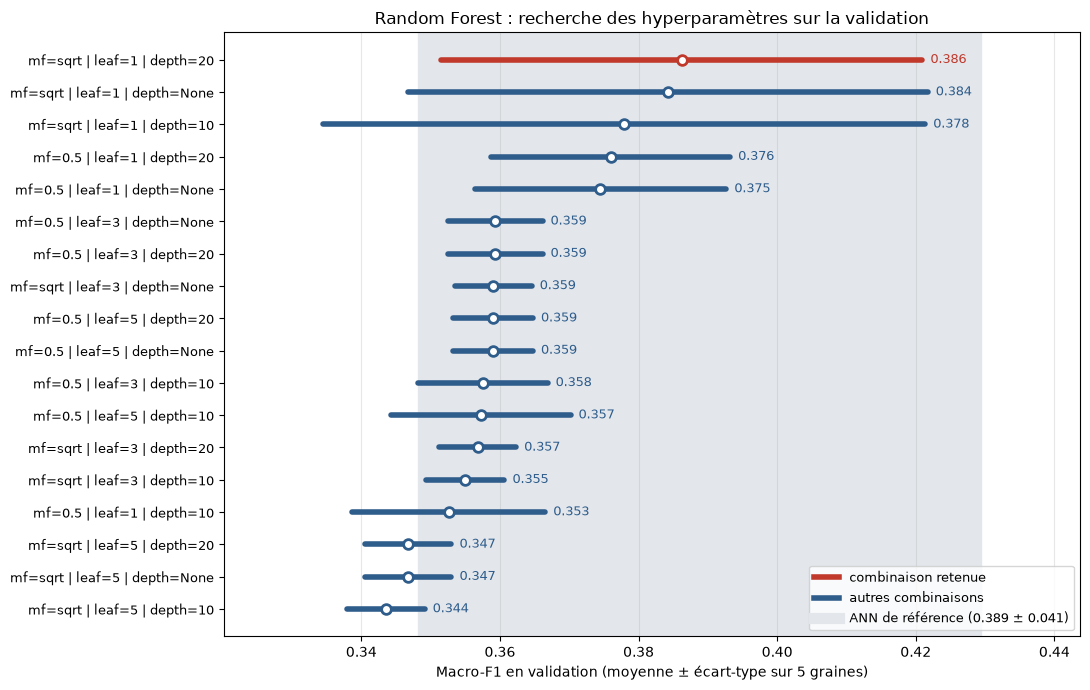

In [11]:
fig, ax = plt.subplots(figsize=(11, 7))
ordre = recap_grille.index[::-1]
for yi, cfg in enumerate(ordre):
    m, s = recap_grille.loc[cfg, "f1"], recap_grille.loc[cfg, "f1_sd"]
    c = "#c0392b" if cfg == MEILLEUR_RF else "#2e5c8b"
    ax.plot([m - s, m + s], [yi, yi], color=c, lw=4, solid_capstyle="round")
    ax.plot(m, yi, "o", color="white", mec=c, mew=2, ms=7)
    ax.text(m + s, yi, f"  {m:.3f}", va="center", fontsize=9, color=c)
m_ann, s_ann = ann["val_f1_macro"].mean(), ann["val_f1_macro"].std()
ax.axvspan(m_ann - s_ann, m_ann + s_ann, color="#e3e7ec", zorder=0)
ax.set_yticks(range(len(ordre)), ordre, fontsize=9)
ax.set_xlabel("Macro-F1 en validation (moyenne ± écart-type sur 5 graines)")
ax.margins(x=0.15)
ax.grid(axis="x", alpha=0.3)
ax.legend(handles=[Line2D([0], [0], color="#c0392b", lw=4, label="combinaison retenue"),
                   Line2D([0], [0], color="#2e5c8b", lw=4, label="autres combinaisons"),
                   Line2D([0], [0], color="#e3e7ec", lw=8, label=f"ANN de référence ({m_ann:.3f} ± {s_ann:.3f})")],
          loc="lower right", fontsize=9)
ax.set_title("Random Forest : recherche des hyperparamètres sur la validation")
plt.tight_layout()
plt.savefig(os.path.join(DOSSIER_RF, "recherche_hyperparametres.png"), dpi=150)
plt.show()

Les combinaisons à feuilles plus grandes sont plus stables (écart-type d’environ 0,007), mais régulièrement moins bonnes (environ 0,359) : en simplifiant les arbres, elles renoncent à reconnaître les classes rares.

#### Déséquilibre des classes

Mêmes méthodes que pour l'ANN : sans correction, poids de classe, suréchantillonnage, SMOTE.

In [13]:
# Même menu que pour l'ANN, appliqué à l'entraînement seulement
METHODES_DESEQ = ["Sans correction", "Poids de classe", "Suréchantillonnage", "SMOTE"]


class RFDeseq:
    """Random Forest + méthode de rééquilibrage, appliquée seulement aux données sur lesquelles on l'entraîne."""
    def __init__(self, methode, params, graine):
        self.methode, self.params, self.graine = methode, params, graine

    def fit(self, X, y):
        poids = None
        if self.methode == "Poids de classe":
            poids = "balanced"                                   # n / (K x n_k)
        elif self.methode == "Suréchantillonnage":
            X, y = RandomOverSampler(random_state=self.graine).fit_resample(X, y)
        elif self.methode == "SMOTE":
            effectifs = np.bincount(y)
            k = min(5, effectifs[effectifs > 0].min() - 1)         # k voisins : au plus la plus petite classe - 1
            echantillonneur = SMOTE(k_neighbors=k, random_state=self.graine) if k >= 1 else RandomOverSampler(random_state=self.graine)
            X, y = echantillonneur.fit_resample(X, y)
        self.foret_ = RandomForestClassifier(**self.params, class_weight=poids, random_state=self.graine, n_jobs=-1).fit(X, y)
        return self

    def predict(self, X):
        return self.foret_.predict(X)


resultats_deseq, rappels_deseq = [], {}
for methode in METHODES_DESEQ:
    for graine in GRAINES:
        ligne, _, pred = evaluer(lambda g: RFDeseq(methode, PARAMS_RF, g), graine, methode)
        resultats_deseq.append(ligne)
        rappels_deseq[(methode, graine)] = recall_score(y_val, pred, average=None, labels=range(N_CLASSES), zero_division=0)
    f1s = [r["val_f1_macro"] for r in resultats_deseq if r["config"] == methode]
    print(f"{methode:20s} | Macro-F1 val = {np.mean(f1s):.3f} ± {np.std(f1s, ddof=1):.3f}")
resultats_deseq = pd.DataFrame(resultats_deseq)
resultats_deseq.to_csv(os.path.join(DOSSIER_RF, "desequilibre_resultats.csv"), index=False)

# Rappel par classe (moyenne sur 5 graines)
ordre_classes = np.argsort(np.bincount(y_train))[::-1]
rappel_classes = pd.DataFrame({m: np.mean([rappels_deseq[(m, g)] for g in GRAINES], axis=0)[ordre_classes]
                               for m in METHODES_DESEQ}, index=[noms_courts[k] for k in ordre_classes]).T
rappel_classes.round(2).to_csv(os.path.join(DOSSIER_RF, "desequilibre_rappel_par_classe.csv"))


Sans correction      | Macro-F1 val = 0.386 ± 0.035
Poids de classe      | Macro-F1 val = 0.440 ± 0.004
Suréchantillonnage   | Macro-F1 val = 0.450 ± 0.012
SMOTE                | Macro-F1 val = 0.367 ± 0.017


Le suréchantillonnage donne le meilleur Macro-F1 en validation, synonime de meilleurs compromis entre la reconnaissance des classes et leur prediction 

#### Choix de la méthode de rééquilibrage

On ne change que si le Macro-F1 progresse nettement par rapport à « Sans correction ».

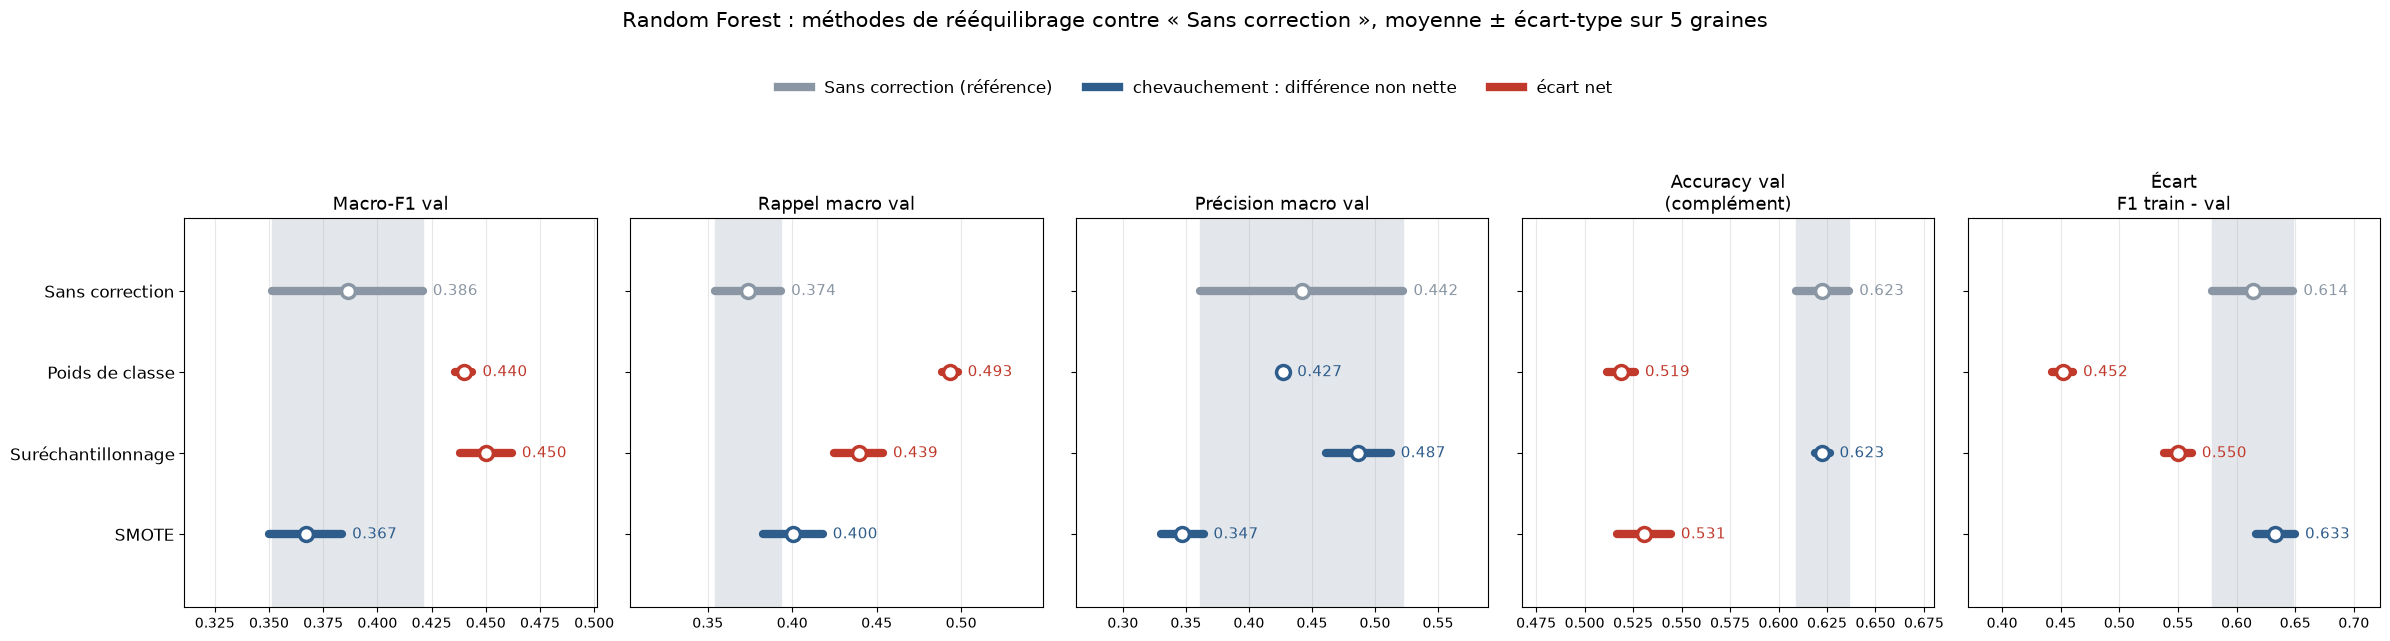

Méthodes avec un gain net de Macro-F1 : ['Poids de classe', 'Suréchantillonnage']
Méthode retenue sous reserve : Suréchantillonnage

Rappel par classe (moyenne sur 5 graines) :


,Rubber,Savannas,Coffee,Forest,Human,Wetlands,Water,Bare
Sans correction,0.84,0.07,0.41,0.23,0.33,0.10,1.0,0.0
Poids de classe,0.51,0.27,0.71,0.55,0.67,0.25,1.0,0.0
Suréchantillonnage,0.78,0.12,0.53,0.37,0.47,0.25,1.0,0.0
SMOTE,0.62,0.13,0.60,0.47,0.33,0.05,1.0,0.0


In [14]:
bandes_chevauchement(resultats_deseq, METHODES_DESEQ, "Sans correction",
                     "Random Forest : méthodes de rééquilibrage contre « Sans correction », moyenne ± écart-type sur 5 graines",
                     os.path.join(DOSSIER_RF, "desequilibre_chevauchement.png"), "Sans correction (référence)")

# Règle de l'ANN : on change seulement si le Macro-F1 progresse nettement
st = resultats_deseq.groupby("config")["val_f1_macro"].agg(["mean", "std"])
haut_ref = st.loc["Sans correction", "mean"] + st.loc["Sans correction", "std"]
nettes = [m for m in METHODES_DESEQ[1:] if st.loc[m, "mean"] - st.loc[m, "std"] > haut_ref]
METHODE_RF = max(nettes, key=lambda m: st.loc[m, "mean"]) if nettes else "Sans correction"
print("Méthodes avec un gain net de Macro-F1 :", nettes if nettes else "aucune")
print("Méthode retenue sous reserve :", METHODE_RF)

print("\nRappel par classe (moyenne sur 5 graines) :")

display(rappel_classes.round(2))

- le suréchantillonnage améliore nettement le Macro-F1 (0,450 contre 0,386) et le rappel macro (0,439 contre 0,374) sans faire baisser l’accuracy.Les classes minoritaires sont mieux reconnues (Coffee 0,53, Human 0,47, Forest 0,37, Wetlands 0,25) tandis que Rubber reste bien reconnu (0,78). L’eau est toujours parfaitement reconnue, mais Bare Soil jamais, et Savannas reste faible (0,12).

- Les poids de classe font aussi progresser le Macro-F1 (0,440), mais l’accuracy chute .
- SMOTE n’apporte aucun gain net. 

la forêt reconnaît mieux Coffee, Human, Wetlands et Savannas, au prix d’un Rubber (0,78 contre 0,90 avec ANN) et d’une Forest (0,37 contre 0,47 avec ANN) un peu en retrait. 
du fait qu'une forêt prédit presque parfaitement son entraînement, l'ecart train-val ne suffit donc pas à écarter un surapprentissage, que la validation croisée aléatoire et spatiale permettra de vérifier.

#### Random Forest retenu


Réglages de RF.1 et suréchantillonnage  comparés à l’ANN de référence.

In [15]:
# Random Forest retenu (réglages de RF.1, rééquilibrage de RF.4) : 5 graines
NOM_RF = "Random Forest"
resultats_rf, f1_classes_rf, predictions_rf = [], {}, {}
for graine in GRAINES:
    ligne, f1c, pred = evaluer(lambda g: RFDeseq(METHODE_RF, PARAMS_RF, g), graine, NOM_RF)
    resultats_rf.append(ligne)
    f1_classes_rf[graine], predictions_rf[graine] = f1c, pred
resultats_rf = pd.DataFrame(resultats_rf)
resultats_rf.to_csv(os.path.join(DOSSIER_RF, "resultats_detailles.csv"), index=False)

# Tableau récapitulatif : ANN de référence contre Random Forest (moyenne ± écart-type sur 5 graines)
comparaison_rf = pd.concat([ann, resultats_rf], ignore_index=True)
cols = ["val_f1_macro", "val_recall_macro", "val_precision_macro", "val_mcc", "val_accuracy", "ecart_f1_train_val", "temps_s"]
recap_rf = comparaison_rf.groupby("config")[cols].agg(["mean", "std"]).loc[[REF_ANN, NOM_RF]]
tableau_rf = pd.DataFrame(index=recap_rf.index)
for c in cols:
    dec = 1 if c == "temps_s" else 3
    tableau_rf[c] = [f"{m:.{dec}f} ± {s:.{dec}f}" for m, s in zip(recap_rf[(c, "mean")], recap_rf[(c, "std")])]
tableau_rf.to_csv(os.path.join(DOSSIER_RF, "recapitulatif.csv"))


#### Comparaison avec l'ANN

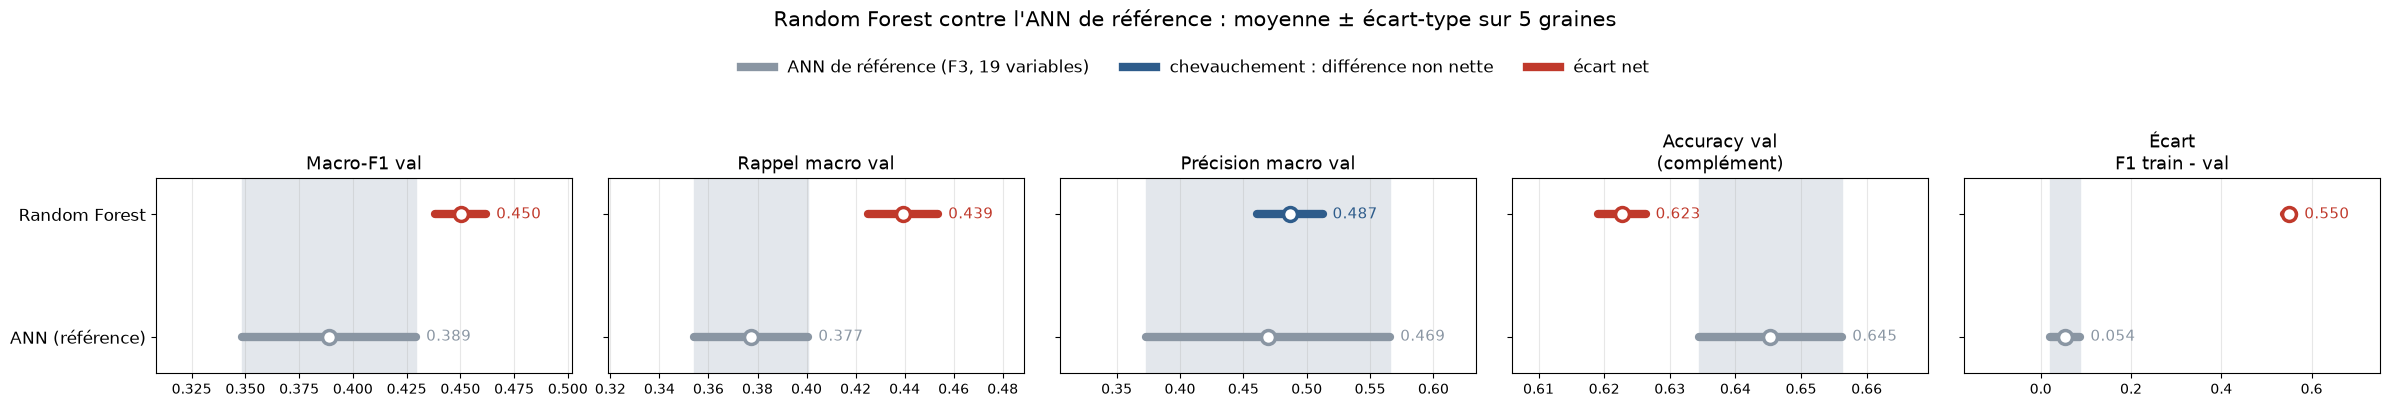

,val_f1_macro,val_recall_macro,val_precision_macro,val_mcc,val_accuracy,ecart_f1_train_val,temps_s
config,,,,,,,
ANN (référence),0.389 ± 0.041,0.377 ± 0.023,0.469 ± 0.097,0.330 ± 0.025,0.645 ± 0.011,0.054 ± 0.034,35.2 ± 3.4
Random Forest,0.450 ± 0.012,0.439 ± 0.014,0.487 ± 0.026,0.353 ± 0.013,0.623 ± 0.004,0.550 ± 0.012,5.4 ± 1.1


In [16]:
bandes_chevauchement(comparaison_rf, [NOM_RF, REF_ANN], REF_ANN,
                     "Random Forest contre l'ANN de référence : moyenne ± écart-type sur 5 graines",
                     os.path.join(DOSSIER_RF, "chevauchement_ann.png"), "ANN de référence (F3, 19 variables)")

display(tableau_rf)

La forêt aléatoire, avec suréchantillonnage, se distingue nettement de l’ANN de référence : son Macro-F1  et son rappel macro présentent un écart net. Sa précision macro est un peu plus élevée en moyenne, mais les intervalles se chevauchent.
Il ressort donc que la forêt retrouve mieux les classes sans multiplier les fausses alarmes. Son accuracy est en revanche nettement plus basse car elle prédit un peu moins souvent Rubber, la classe majoritaire.

Ce résultat rejoint la littérature, selon laquelle les modèles à base d’arbres égalent ou dépassent souvent les réseaux de neurones sur des données tabulaires.

#### F1 par classe et matrice de confusion

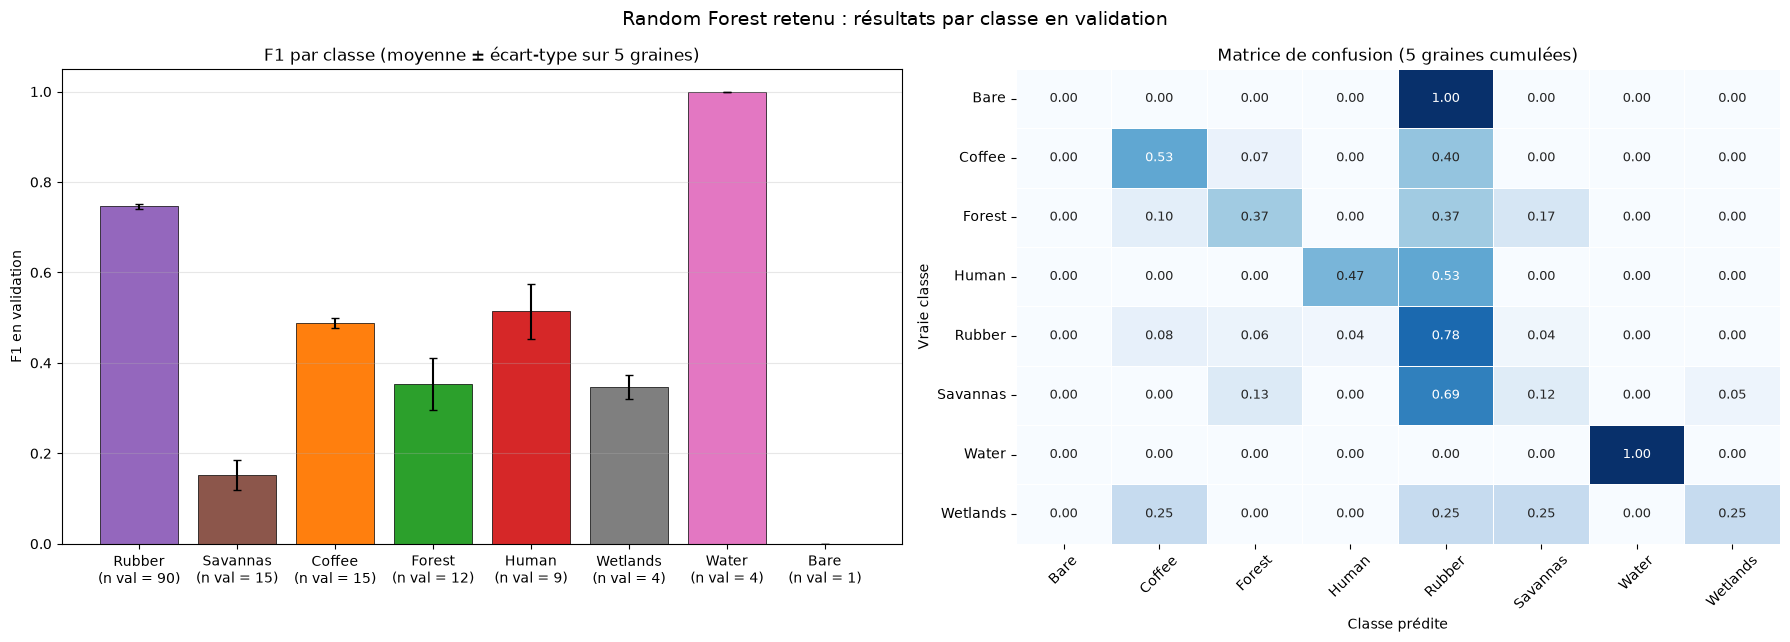

In [17]:
ordre_classes = np.argsort(np.bincount(y_train))[::-1]          # de la plus fréquente à la plus rare
f1s = np.array([f1_classes_rf[g] for g in GRAINES])[:, ordre_classes]

fig, axes = plt.subplots(1, 2, figsize=(18, 6.5), gridspec_kw={"width_ratios": [1.1, 1]})
axes[0].bar(range(N_CLASSES), f1s.mean(axis=0), yerr=f1s.std(axis=0), capsize=3,
            color=[COULEURS_CLASSES[NOMS_CLASSES[k]] for k in ordre_classes], edgecolor="black", lw=0.5)
axes[0].set_xticks(range(N_CLASSES), [f"{noms_courts[k]}\n(n val = {np.sum(y_val == k)})" for k in ordre_classes])
axes[0].set_ylim(0, 1.05)
axes[0].set_ylabel("F1 en validation")
axes[0].grid(axis="y", alpha=0.3)
axes[0].set_title("F1 par classe (moyenne ± écart-type sur 5 graines)")

cm = sum(confusion_matrix(y_val, predictions_rf[g], labels=range(N_CLASSES)) for g in GRAINES)
sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False,
            xticklabels=noms_courts, yticklabels=noms_courts, annot_kws={"fontsize": 9},
            linewidths=0.5, linecolor="white", ax=axes[1])
axes[1].set_xlabel("Classe prédite")
axes[1].set_ylabel("Vraie classe")
axes[1].tick_params(axis="x", rotation=45)
axes[1].tick_params(axis="y", rotation=0)
axes[1].set_title("Matrice de confusion (5 graines cumulées)")
fig.suptitle("Random Forest retenu : résultats par classe en validation", fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(DOSSIER_RF, "f1_classes_confusion.png"), dpi=150)
plt.show()

Comme pour l’ANN, plusieurs classes restent confondues avec Rubber : Savannas (69 % de ses observations prédites Rubber), Human (53 %), Coffee (40 %) et Forest (37 %). Bare Soil, avec une seule observation en validation, est toujours classée Rubber.

Les classes minoritaires sont cependant mieux reconnues qu’avec l’ANN : Coffee (rappel de 0,53), Human (0,47) et Wetlands (0,25). 
Water reste parfaitement reconnue (F1 = 1,00), et Rubber garde un F1 élevé et très stable entre graines (environ 0,75). Forest se partage entre Rubber (37 %), Savannas (17 %) et Coffee (10 %).  les confusions entre classes végétales comme c'est le cas de wetland rejoignent la proximité de leurs signatures spectrales observée dans l’analyse exploratoire.

#### Validation aléatoire et spatiale

f1_macro   rappel_macro       accuracy
config             validation                                             
ANN (référence)    aléatoire   0.361 ± 0.033  0.350 ± 0.026  0.641 ± 0.011
                   spatiale    0.288 ± 0.070  0.291 ± 0.074  0.636 ± 0.103
RF sans correction aléatoire   0.373 ± 0.071  0.353 ± 0.058  0.633 ± 0.043
                   spatiale    0.251 ± 0.085  0.252 ± 0.073  0.617 ± 0.106
Random Forest      aléatoire   0.416 ± 0.060  0.400 ± 0.055  0.604 ± 0.049
                   spatiale    0.333 ± 0.104  0.329 ± 0.101  0.601 ± 0.051

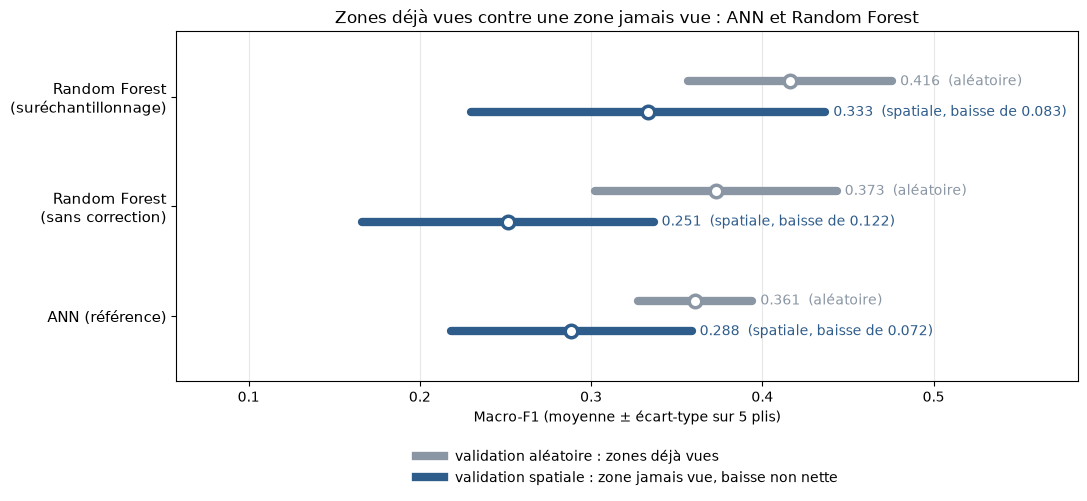

In [18]:
# On ajoute la forêt sans correction : si le suréchantillonnage faisait surapprendre, son gain disparaîtrait en spatial
NOM_RF_REF = "RF sans correction"
vc_rf = validation_croisee(lambda g: RFDeseq(METHODE_RF, PARAMS_RF, g), NOM_RF)
vc_rf_ref = validation_croisee(lambda g: RFDeseq("Sans correction", PARAMS_RF, g), NOM_RF_REF)
pd.concat([vc_rf, vc_rf_ref]).to_csv(os.path.join(DOSSIER_RF, "validation_aleatoire_spatiale.csv"), index=False)
vc = pd.concat([ann_vc, vc_rf_ref, vc_rf], ignore_index=True)
recap_vc = vc.groupby(["config", "validation"])[["f1_macro", "rappel_macro", "accuracy"]].agg(["mean", "std"])
tableau_vc = pd.DataFrame(index=recap_vc.index)
for c in ["f1_macro", "rappel_macro", "accuracy"]:
    tableau_vc[c] = [f"{m:.3f} ± {s:.3f}" for m, s in zip(recap_vc[(c, "mean")], recap_vc[(c, "std")])]
display(tableau_vc)

modeles_vc = [NOM_RF, NOM_RF_REF, REF_ANN]                       # de haut en bas : RF retenu, RF sans correction, ANN
etiquettes_vc = {NOM_RF: f"Random Forest\n({METHODE_RF.lower()})", NOM_RF_REF: "Random Forest\n(sans correction)", REF_ANN: "ANN (référence)"}
fig, ax = plt.subplots(figsize=(11, 5.2))
for yi, config in enumerate(modeles_vc[::-1]):
    m_a, s_a = recap_vc.loc[(config, "aléatoire"), ("f1_macro", "mean")], recap_vc.loc[(config, "aléatoire"), ("f1_macro", "std")]
    m_s, s_s = recap_vc.loc[(config, "spatiale"), ("f1_macro", "mean")], recap_vc.loc[(config, "spatiale"), ("f1_macro", "std")]
    c_s = "#c0392b" if (m_s + s_s < m_a - s_a) else "#2e5c8b"
    for m, s, c, dy, nom in [(m_a, s_a, "#8a96a3", 0.14, "aléatoire"), (m_s, s_s, c_s, -0.14, "spatiale")]:
        ax.plot([m - s, m + s], [yi + dy, yi + dy], color=c, lw=6, solid_capstyle="round")
        ax.plot(m, yi + dy, "o", color="white", mec=c, mew=2.5, ms=9)
        ax.text(m + s, yi + dy, f"  {m:.3f}  ({nom}, baisse de {m_a - m_s:.3f})" if nom == "spatiale" else f"  {m:.3f}  ({nom})",
                va="center", fontsize=10, color=c)
ax.set_yticks(range(len(modeles_vc)), [etiquettes_vc[c] for c in modeles_vc[::-1]], fontsize=11)
ax.set_xlabel("Macro-F1 (moyenne ± écart-type sur 5 plis)")
ax.margins(x=0.35, y=0.2)
ax.grid(axis="x", alpha=0.3)
ax.legend(handles=[Line2D([0], [0], color="#8a96a3", lw=6, label="validation aléatoire : zones déjà vues"),
                   Line2D([0], [0], color="#2e5c8b", lw=6, label="validation spatiale : zone jamais vue, baisse non nette"),],
          loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=1, frameon=False, fontsize=10)
ax.set_title("Zones déjà vues contre une zone jamais vue : ANN et Random Forest")
plt.tight_layout()
plt.savefig(os.path.join(DOSSIER_RF, "validation_aleatoire_spatiale.png"), dpi=150)
plt.show()

En validation spatiale, tous les modèles perdent en performance. Certaines classes sont concentrées dans une seule zone : l’eau, par exemple, se trouve presque entièrement dans le bloc 2. Quand ce bloc sert de test, les modèles n’ont presque jamais vu d’eau à l’entraînement et ne peuvent pas la reconnaître, ce qui fait baisser le Macro-F1. 
Quelle que soit la validation, la forêt suréchantillonnée reste en tête en moyenne (0,416 en aléatoire, 0,333 en spatial), même si les intervalles se chevauchent. Elle ne montre pas de signe de surapprentissage lié aux copies : son Macro-F1 baisse moins que celui de la forêt sans correction en zone nouvelle. L’ANN reste le plus stable d’une zone à l’autre (baisse de 0,072), mais à un niveau plus bas.

#### Apercu de l'arbre

530 arbres ; profondeur réelle des 3 premiers : [16, 20, 16]


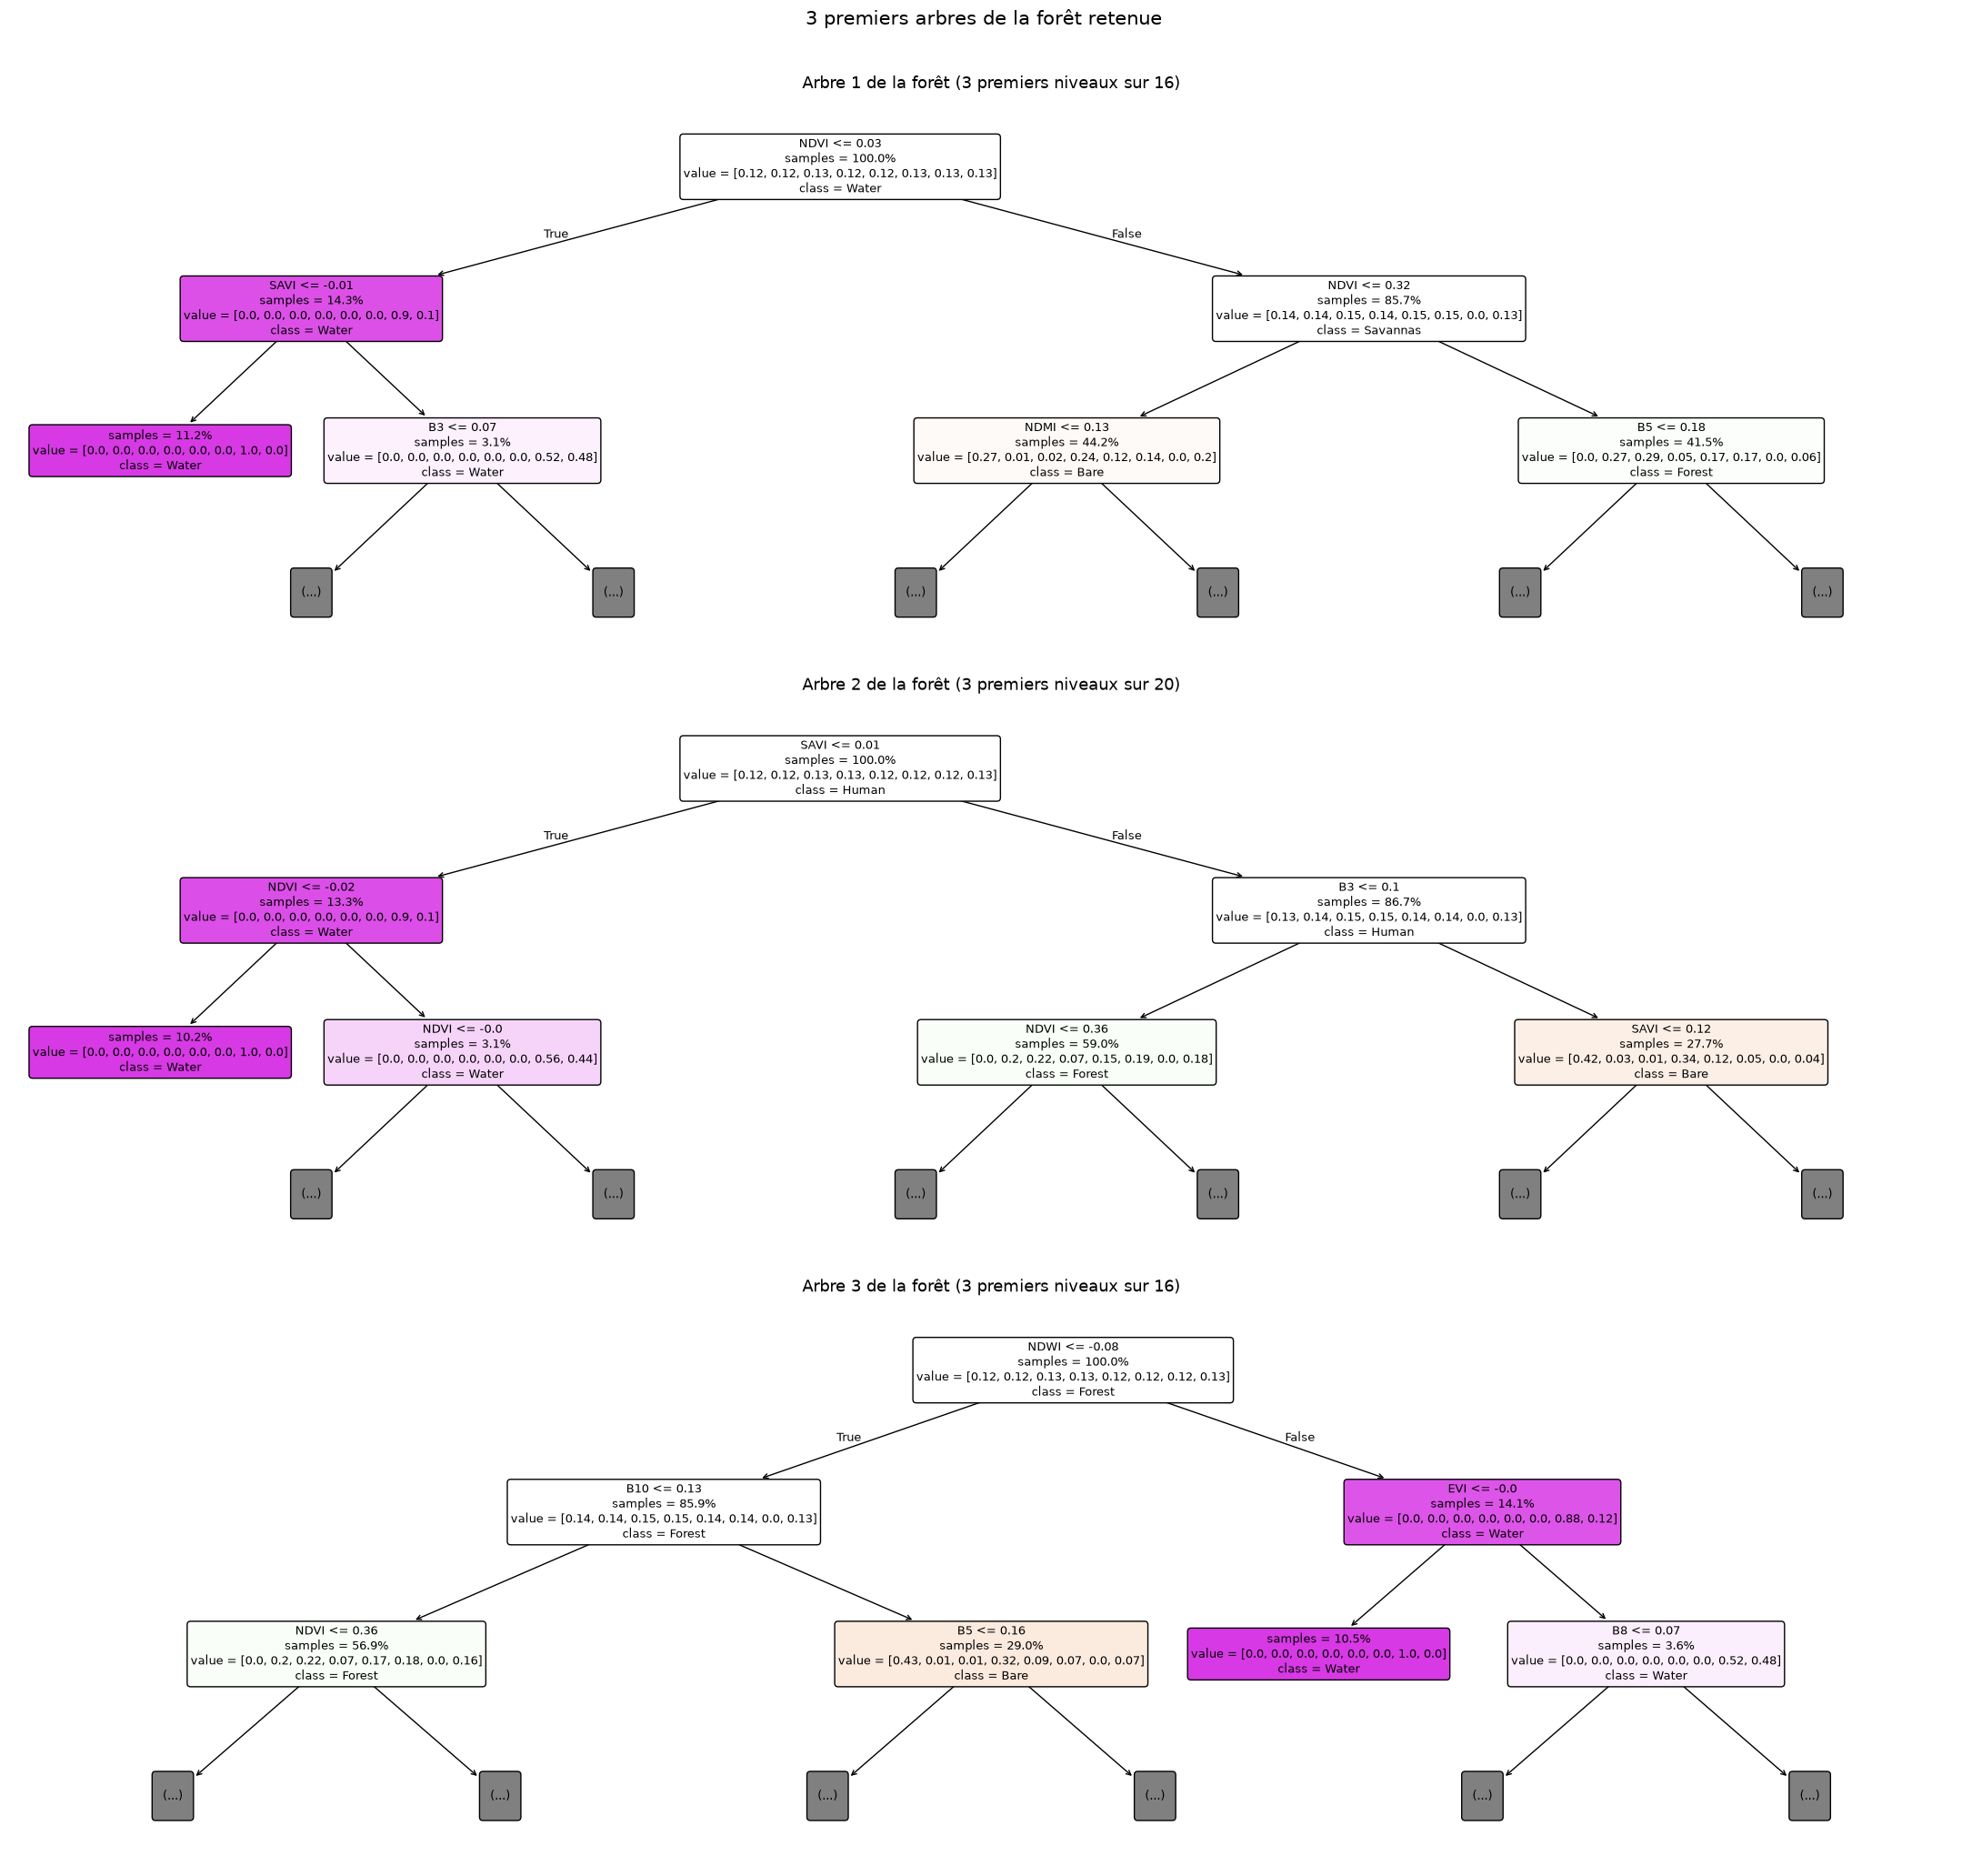

In [19]:

from sklearn.tree import plot_tree

X_brut_train = data.loc[idx_train, VARIABLES].to_numpy(dtype="float32")
foret_affichage = RFDeseq(METHODE_RF, PARAMS_RF, GRAINES[0]).fit(X_brut_train, y_train).foret_
print(f"{len(foret_affichage.estimators_)} arbres ; profondeur réelle des 3 premiers :",
      [a.get_depth() for a in foret_affichage.estimators_[:3]])

fig, axes = plt.subplots(3, 1, figsize=(22, 21))
for k, ax in enumerate(axes):
    plot_tree(foret_affichage.estimators_[k], max_depth=2, feature_names=VARIABLES, class_names=noms_courts,
              filled=True, rounded=True, impurity=False, proportion=True, precision=2, fontsize=9, ax=ax)
    ax.set_title(f"Arbre {k + 1} de la forêt (3 premiers niveaux sur {foret_affichage.estimators_[k].get_depth()})", fontsize=13)
fig.suptitle("3 premiers arbres de la forêt retenue ", fontsize=15)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig(os.path.join(DOSSIER_RF, "arbres_foret.png"), dpi=130)
plt.show()

sur 530 arbre qui composent la foret , Les trois  premiers arbres affichés commencent chacun par une question différente (NDVI, SAVI ou NDWI), signe que le tirage au hasard des observations et des variables rend les arbres de la forêt différents les uns des autres. Tous isolent pourtant l’eau dès les premiers niveaux, ce qui confirme qu’elle est la classe la plus facile à séparer.

#### Configuration finale

Enregistrée dans `resultats/modeles_finaux/config_rf.json`.

In [20]:
# Configuration finale du Random Forest, figée avant le test final
def moyenne_ecart(serie):
    return {"moyenne": round(float(serie.mean()), 3), "ecart_type": round(float(serie.std()), 3)}

CONFIG_RF_FINAL = {
    "modele": "Random Forest",
    "hyperparametres": PARAMS_RF,
    "choix_hyperparametres": "meilleur Macro-F1 moyen en validation (5 graines) parmi la grille",
    "grille": {k: [str(x) for x in v] for k, v in GRILLE_RF.items()},
    "desequilibre": METHODE_RF,
    "desequilibre_application": "entraînement seulement (validation et test intacts)",
    "desequilibre_regle": "changement seulement si gain net de Macro-F1 sur « Sans correction » (même règle que l'ANN)",
    "variables": VARIABLES,
    "n_variables": len(VARIABLES),
    "standardisation": "StandardScaler appris sur l'entraînement (sans effet sur les arbres)",
    "graines": GRAINES,
    "seed_partition": SEED_PARTITION,
    "validation_fixe": {                                  # 5 graines, validation de 150 observations
        "f1_macro": moyenne_ecart(resultats_rf["val_f1_macro"]),
        "rappel_macro": moyenne_ecart(resultats_rf["val_recall_macro"]),
        "precision_macro": moyenne_ecart(resultats_rf["val_precision_macro"]),
        "accuracy": moyenne_ecart(resultats_rf["val_accuracy"]),
    },
    "validation_croisee_dev": {                           # 5 plis, entraînement + validation
        schema: {"f1_macro_moyenne": round(float(recap_vc.loc[(NOM_RF, schema), ("f1_macro", "mean")]), 3),
                 "f1_macro_ecart_type": round(float(recap_vc.loc[(NOM_RF, schema), ("f1_macro", "std")]), 3)}
        for schema in PLIS},
}

os.makedirs(DOSSIER_FINAL, exist_ok=True)
with open(os.path.join(DOSSIER_FINAL, "config_rf.json"), "w", encoding="utf-8") as f:
    json.dump(CONFIG_RF_FINAL, f, ensure_ascii=False, indent=2, default=str)
print(json.dumps({k: v for k, v in CONFIG_RF_FINAL.items() if k != "variables"}, ensure_ascii=False, indent=2, default=str))

{
  "modele": "Random Forest",
  "hyperparametres": {
    "n_estimators": 530,
    "max_features": "sqrt",
    "min_samples_leaf": 1,
    "max_depth": 20
  },
  "choix_hyperparametres": "meilleur Macro-F1 moyen en validation (5 graines) parmi la grille",
  "grille": {
    "n_estimators": [
      "530"
    ],
    "max_features": [
      "sqrt",
      "0.5"
    ],
    "min_samples_leaf": [
      "1",
      "3",
      "5"
    ],
    "max_depth": [
      "None",
      "10",
      "20"
    ]
  },
  "desequilibre": "Suréchantillonnage",
  "desequilibre_application": "entraînement seulement (validation et test intacts)",
  "desequilibre_regle": "changement seulement si gain net de Macro-F1 sur « Sans correction » (même règle que l'ANN)",
  "n_variables": 19,
  "standardisation": "StandardScaler appris sur l'entraînement (sans effet sur les arbres)",
  "graines": [
    0,
    1,
    2,
    3,
    4
  ],
  "seed_partition": 42,
  "validation_fixe": {
    "f1_macro": {
      "moyenne": 0.45,
   

#### Synthese Random Forest 

Synthèse de Random Forest

La forêt retenue (530 arbres, max_features = sqrt, avec suréchantillonnage) dépasse nettement l’ANN en Macro-F1 (0,450 contre 0,389) et reconnaît mieux les classes minoritaires, au prix d’une accuracy un peu plus basse. Elle reste en tête en zone nouvelle (0,333 contre 0,288), sans surapprentissage lié au suréchantillonnage.

Limites: Les confusions avec Rubber persistent pour Savannas, Human, Coffee et Forest, et Bare Soil n’est jamais reconnue (une seule observation en validation). Comme pour l’ANN, la limite principale reste la proximité spectrale entre classes végétales, que ni le modèle ni le rééquilibrage ne peuvent lever.

La configuration de la forêt est figée dans config_rf.json. Elle sera comparée au SVM et à XGBoost avec le même protocole, puis évaluée une seule fois sur le jeu de test.

### SVM

#### Préparation

contrairement au au deux premiers modeles, il nous sera pas necessaire ici de fixer des graines.

In [21]:


DOSSIER_SVM = os.path.join("resultats", "modeles_classiques", "svm")
os.makedirs(DOSSIER_SVM, exist_ok=True)
CRITERES_BOOT = {"val_f1_macro": lambda v, p: f1_score(v, p, average="macro", zero_division=0),
                 "val_recall_macro": lambda v, p: recall_score(v, p, average="macro", zero_division=0),
                 "val_precision_macro": lambda v, p: precision_score(v, p, average="macro", zero_division=0),
                 "val_accuracy": accuracy_score}


def ecarts_bootstrap(pred, n=500, graine=0):
    """Écart-type de chaque critère quand on rééchantillonne la validation avec remise."""
    rng = np.random.default_rng(graine)
    tirages = [rng.integers(0, len(y_val), len(y_val)) for _ in range(n)]
    return {c: np.std([f(y_val[t], pred[t]) for t in tirages], ddof=1) for c, f in CRITERES_BOOT.items()}


def bandes_avec_ecarts(df, configs, reference, titre, fichier, etiquette_ref, ecarts=None):
    """Bandes de chevauchement ; « ecarts » remplace l'écart-type entre graines quand il est nul (SVM)."""
    criteres = [("val_f1_macro", "Macro-F1 val"), ("val_recall_macro", "Rappel macro val"),
                ("val_precision_macro", "Précision macro val"), ("val_accuracy", "Accuracy val\n(complément)"),
                ("ecart_f1_train_val", "Écart\nF1 train - val")]
    stats = df.groupby("config")[[c for c, _ in criteres]].agg(["mean", "std"]).loc[configs]
    fig, axes = plt.subplots(1, len(criteres), figsize=(24, 1.6 + 1.1 * len(configs)), sharey=True)
    y_pos = np.arange(len(configs))[::-1]
    for ax, (col, t) in zip(axes, criteres):
        m, s = stats[(col, "mean")], stats[(col, "std")].fillna(0).copy()
        if ecarts is not None:
            for cfg in configs:
                if cfg in ecarts:
                    s[cfg] = max(s[cfg], ecarts[cfg].get(col if col != "ecart_f1_train_val" else "val_f1_macro", 0))
        bas_ref, haut_ref = m[reference] - s[reference], m[reference] + s[reference]
        ax.axvspan(bas_ref, haut_ref, color="#e3e7ec")
        for yi, cfg in zip(y_pos, configs):
            bas, haut = m[cfg] - s[cfg], m[cfg] + s[cfg]
            c = "#8a96a3" if cfg == reference else ("#2e5c8b" if bas <= haut_ref and haut >= bas_ref else "#c0392b")
            ax.plot([bas, haut], [yi, yi], color=c, lw=6, solid_capstyle="round")
            ax.plot(m[cfg], yi, "o", color="white", mec=c, mew=2.5, ms=10)
            ax.text(haut, yi, f"  {m[cfg]:.3f}", va="center", fontsize=11, color=c)
        ax.set_title(t, fontsize=13)
        ax.margins(x=0.35, y=0.3)
        ax.grid(axis="x", alpha=0.3)
    axes[0].set_yticks(y_pos, configs)
    axes[0].tick_params(axis="y", labelsize=12)
    legende = [Line2D([0], [0], color="#8a96a3", lw=6, label=etiquette_ref),
               Line2D([0], [0], color="#2e5c8b", lw=6, label="chevauchement : différence non nette"),
               Line2D([0], [0], color="#c0392b", lw=6, label="écart net")]
    fig.legend(handles=legende, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 0.97), frameon=False, fontsize=12)
    fig.suptitle(titre, fontsize=15, y=1.06)
    plt.tight_layout(rect=[0, 0, 1, 0.88])
    plt.savefig(fichier, dpi=200, bbox_inches="tight")
    plt.show()
    return stats, s

#### Recherche des hyperparamètres

 grace à l'analyse exploratoire, nous sommes en mesure de nous pencher dans cette section sur un Noyau RBF, 16 combinaisons de `C` et `gamma`, sans correction du déséquilibre pour debuter. 

In [22]:
# Noyau RBF ; C = tolérance aux erreurs, gamma = portée de l'influence d'un point
GRILLE_SVM = {"C": [0.1, 1, 10, 100], "gamma": ["scale", 0.01, 0.1, 1]}
combinaisons_svm = [dict(zip(GRILLE_SVM, v)) for v in product(*GRILLE_SVM.values())]
print(f"{len(combinaisons_svm)} combinaisons (une seule évaluation chacune : le SVM ne dépend pas de la graine)")

grille_svm, PARAMS_GRILLE_SVM = [], {}
for params in combinaisons_svm:
    nom = f"C={params['C']} | gamma={params['gamma']}"
    PARAMS_GRILLE_SVM[nom] = params
    ligne, _, _ = evaluer(lambda g: SVC(kernel="rbf", **params), GRAINES[0], nom)
    grille_svm.append({**ligne, "C": params["C"], "gamma": str(params["gamma"])})
grille_svm = pd.DataFrame(grille_svm).sort_values("val_f1_macro", ascending=False)
grille_svm.to_csv(os.path.join(DOSSIER_SVM, "grille_resultats.csv"), index=False)
display(grille_svm[["config", "val_f1_macro", "val_recall_macro", "train_f1_macro", "ecart_f1_train_val"]].round(3))

MEILLEUR_SVM = grille_svm["config"].iloc[0]
PARAMS_SVM = PARAMS_GRILLE_SVM[MEILLEUR_SVM]
print("Combinaison retenue :", MEILLEUR_SVM, "->", PARAMS_SVM)

16 combinaisons (une seule évaluation chacune : le SVM ne dépend pas de la graine)


,config,val_f1_macro,val_recall_macro,train_f1_macro,ecart_f1_train_val
7,C=1 | gamma=1,0.377,0.352,0.627,0.250
14,C=100 | gamma=0.1,0.359,0.368,0.831,0.472
10,C=10 | gamma=0.1,0.359,0.353,0.554,0.195
12,C=100 | gamma=scale,0.335,0.333,0.660,0.325
13,C=100 | gamma=0.01,0.311,0.312,0.455,0.144
8,C=10 | gamma=scale,0.304,0.310,0.472,0.168
6,C=1 | gamma=0.1,0.292,0.299,0.426,0.134
15,C=100 | gamma=1,0.284,0.310,1.000,0.716
11,C=10 | gamma=1,0.282,0.305,0.992,0.710
4,C=1 | gamma=scale,0.278,0.290,0.353,0.076


Combinaison retenue : C=1 | gamma=1 -> {'C': 1, 'gamma': 1}


nous obtenons la combinaisons suivante comme meileur parametre pour son bon compromis ( macro F1 en validation) qui est le critere principale

#### Résultats de la recherche

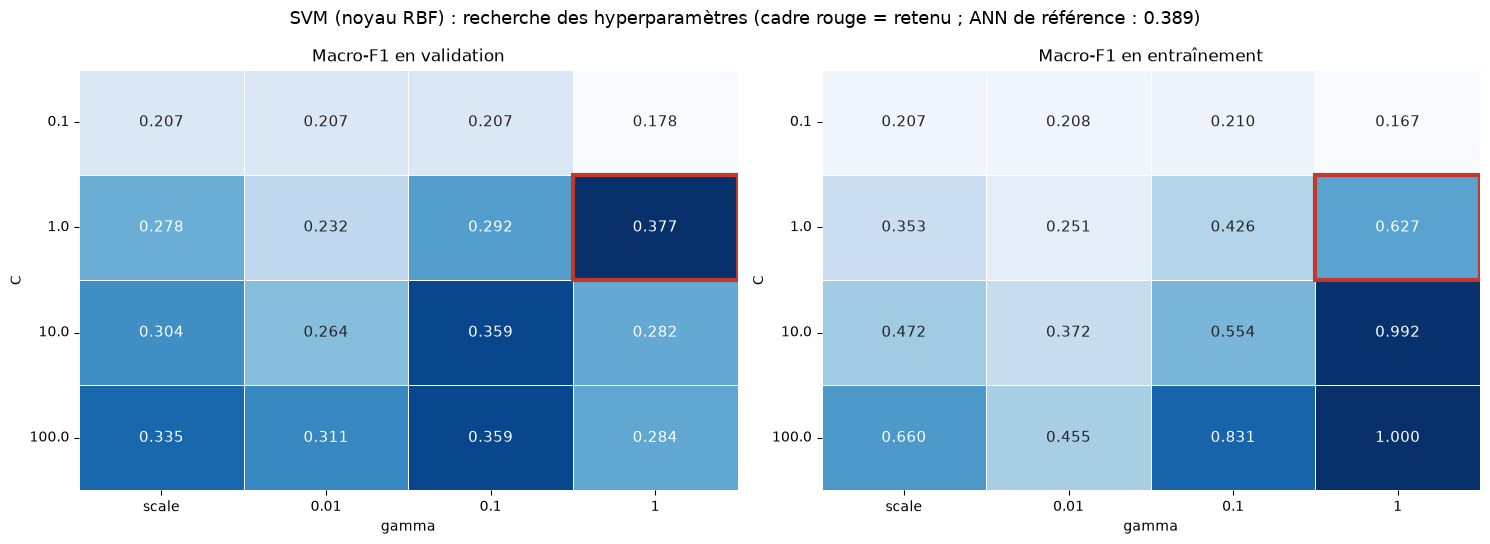

In [23]:
gammas = [str(g) for g in GRILLE_SVM["gamma"]]
carte_f1 = grille_svm.pivot(index="C", columns="gamma", values="val_f1_macro").loc[GRILLE_SVM["C"], gammas]
carte_train = grille_svm.pivot(index="C", columns="gamma", values="train_f1_macro").loc[GRILLE_SVM["C"], gammas]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, carte, titre in [(axes[0], carte_f1, "Macro-F1 en validation"), (axes[1], carte_train, "Macro-F1 en entraînement")]:
    sns.heatmap(carte, annot=True, fmt=".3f", cmap="Blues", cbar=False, linewidths=0.5, linecolor="white",
                annot_kws={"fontsize": 11}, ax=ax)
    i, j = GRILLE_SVM["C"].index(PARAMS_SVM["C"]), gammas.index(str(PARAMS_SVM["gamma"]))
    ax.add_patch(plt.Rectangle((j, i), 1, 1, fill=False, ec="#c0392b", lw=3))
    ax.set_xlabel("gamma")
    ax.set_ylabel("C")
    ax.tick_params(axis="y", rotation=0)
    ax.set_title(titre)
fig.suptitle(f"SVM (noyau RBF) : recherche des hyperparamètres (cadre rouge = retenu ; ANN de référence : "
             f"{ann['val_f1_macro'].mean():.3f})", fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(DOSSIER_SVM, "recherche_hyperparametres.png"), dpi=150)
plt.show()

La combinaison retenue (C = 1, gamma = 1) donne le meilleur Macro-F1 en validation (0,377). Son écart train − val (0,250) traduit un surapprentissage modéré, sans commune mesure avec celui des combinaisons à C et gamma élevés (jusqu’à 0,716, pour une validation de 0,284).

#### Déséquilibre des classes

Mêmes méthodes que pour l'ANN et la forêt : sans correction, poids de classe, suréchantillonnage, SMOTE.

In [24]:
class SVMDeseq:
    """SVM + méthode de rééquilibrage, appliquée seulement aux données sur lesquelles on l'entraîne."""
    def __init__(self, methode, params, graine):
        self.methode, self.params, self.graine = methode, params, graine

    def fit(self, X, y):
        poids = None
        if self.methode == "Poids de classe":
            poids = "balanced"                                   # n / (K x n_k)
        elif self.methode == "Suréchantillonnage":
            X, y = RandomOverSampler(random_state=self.graine).fit_resample(X, y)
        elif self.methode == "SMOTE":
            effectifs = np.bincount(y)
            k = min(5, effectifs[effectifs > 0].min() - 1)         # k voisins : au plus la plus petite classe - 1
            echantillonneur = SMOTE(k_neighbors=k, random_state=self.graine) if k >= 1 else RandomOverSampler(random_state=self.graine)
            X, y = echantillonneur.fit_resample(X, y)
        self.svm_ = SVC(kernel="rbf", **self.params, class_weight=poids).fit(X, y)
        return self

    def predict(self, X):
        return self.svm_.predict(X)


resultats_deseq_svm, preds_deseq_svm, rappels_svm = [], {}, {}
for methode in METHODES_DESEQ:
    for graine in GRAINES:
        ligne, _, pred = evaluer(lambda g: SVMDeseq(methode, PARAMS_SVM, g), graine, methode)
        resultats_deseq_svm.append(ligne)
        preds_deseq_svm[(methode, graine)] = pred
        rappels_svm[(methode, graine)] = recall_score(y_val, pred, average=None, labels=range(N_CLASSES), zero_division=0)
resultats_deseq_svm = pd.DataFrame(resultats_deseq_svm)
resultats_deseq_svm.to_csv(os.path.join(DOSSIER_SVM, "desequilibre_resultats.csv"), index=False)

# Incertitude due à la validation (bootstrap), utilisée quand l'écart-type entre graines est nul
ECARTS_SVM = {m: ecarts_bootstrap(preds_deseq_svm[(m, GRAINES[0])]) for m in METHODES_DESEQ}
for m in METHODES_DESEQ:
    f1s = resultats_deseq_svm.loc[resultats_deseq_svm["config"] == m, "val_f1_macro"]
    print(f"{m:20s} | Macro-F1 val = {f1s.mean():.3f} | écart-type graines = {f1s.std():.3f} | "
          f"écart-type bootstrap = {ECARTS_SVM[m]['val_f1_macro']:.3f}")

# Rappel par classe (moyenne sur 5 graines)
ordre_classes = np.argsort(np.bincount(y_train))[::-1]
rappel_classes_svm = pd.DataFrame({m: np.mean([rappels_svm[(m, g)] for g in GRAINES], axis=0)[ordre_classes]
                                   for m in METHODES_DESEQ}, index=[noms_courts[k] for k in ordre_classes]).T
rappel_classes_svm.round(2).to_csv(os.path.join(DOSSIER_SVM, "desequilibre_rappel_par_classe.csv"))


Sans correction      | Macro-F1 val = 0.377 | écart-type graines = 0.000 | écart-type bootstrap = 0.058
Poids de classe      | Macro-F1 val = 0.364 | écart-type graines = 0.000 | écart-type bootstrap = 0.040
Suréchantillonnage   | Macro-F1 val = 0.300 | écart-type graines = 0.005 | écart-type bootstrap = 0.040
SMOTE                | Macro-F1 val = 0.335 | écart-type graines = 0.008 | écart-type bootstrap = 0.036


#### Choix de la méthode de rééquilibrage


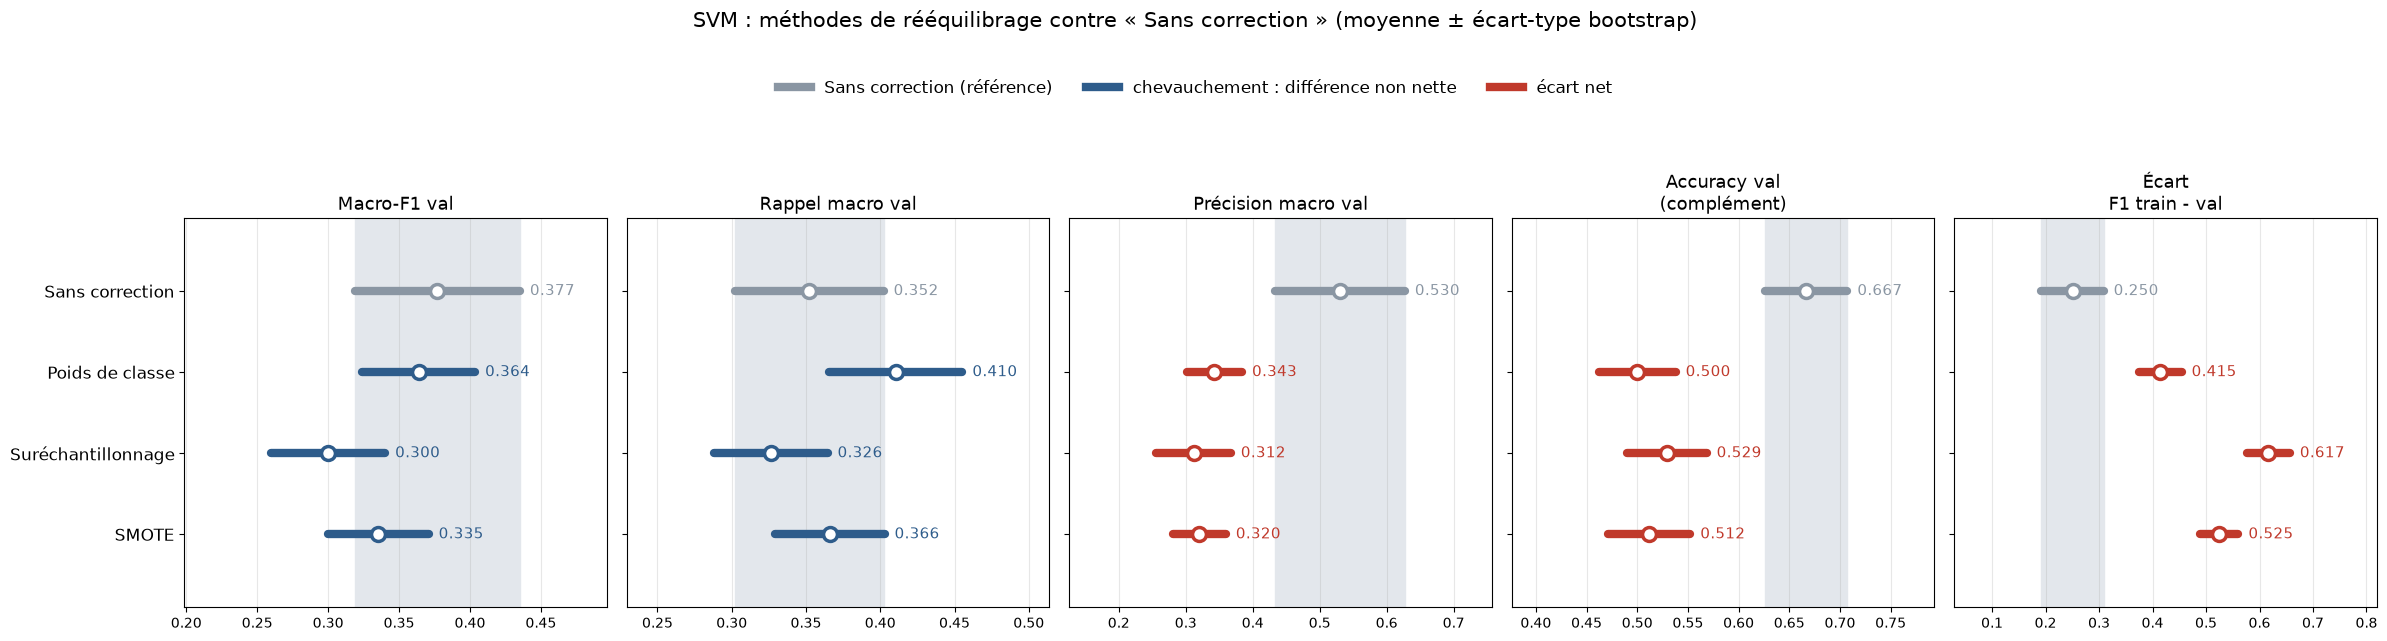

,Macro-F1,é.-t. graines,é.-t. bootstrap,bas,haut,comparaison
Sans correction,0.377,0.000,0.058,0.319,0.435,référence
Poids de classe,0.364,0.000,0.040,0.324,0.404,chevauchement
Suréchantillonnage,0.300,0.005,0.040,0.260,0.340,chevauchement
SMOTE,0.335,0.008,0.036,0.300,0.371,chevauchement


,Rubber,Savannas,Coffee,Forest,Human,Wetlands,Water,Bare
Sans correction,0.97,0.07,0.20,0.33,0.00,0.25,1.0,0.0
Poids de classe,0.53,0.33,0.67,0.42,0.33,0.00,1.0,0.0
Suréchantillonnage,0.70,0.16,0.56,0.08,0.11,0.00,1.0,0.0
SMOTE,0.62,0.17,0.56,0.33,0.24,0.00,1.0,0.0


Méthode retenue : Sans correction


In [27]:
# Bandes de chevauchement : incertitude = écart-type bootstrap (variation due au jeu de validation)
stats_d, ecarts_d = bandes_avec_ecarts(resultats_deseq_svm, METHODES_DESEQ, "Sans correction",
                                       "SVM : méthodes de rééquilibrage contre « Sans correction » (moyenne ± écart-type bootstrap)",
                                       os.path.join(DOSSIER_SVM, "desequilibre_chevauchement.png"),
                                       "Sans correction (référence)", ecarts=ECARTS_SVM)

# Incertitude retenue : la plus grande des deux (graines ou bootstrap) ; pour le SVM, c'est le bootstrap
m_f1 = stats_d[("val_f1_macro", "mean")]
s_graines = resultats_deseq_svm.groupby("config")["val_f1_macro"].std()
s_f1 = {m: max(s_graines[m], ECARTS_SVM[m]["val_f1_macro"]) for m in METHODES_DESEQ}

# Tableau des intervalles et du chevauchement avec « Sans correction »
bas_ref, haut_ref = m_f1["Sans correction"] - s_f1["Sans correction"], m_f1["Sans correction"] + s_f1["Sans correction"]
intervalles = pd.DataFrame({
    "Macro-F1": [m_f1[m] for m in METHODES_DESEQ],
    "é.-t. graines": [s_graines[m] for m in METHODES_DESEQ],
    "é.-t. bootstrap": [ECARTS_SVM[m]["val_f1_macro"] for m in METHODES_DESEQ],
    "bas": [m_f1[m] - s_f1[m] for m in METHODES_DESEQ],
    "haut": [m_f1[m] + s_f1[m] for m in METHODES_DESEQ],
}, index=METHODES_DESEQ)
intervalles["comparaison"] = ["référence" if m == "Sans correction"
                              else ("gain net" if intervalles.loc[m, "bas"] > haut_ref
                                    else ("perte nette" if intervalles.loc[m, "haut"] < bas_ref else "chevauchement"))
                              for m in METHODES_DESEQ]
display(intervalles.round(3))

# Règle de l'ANN : on change seulement si le Macro-F1 progresse nettement
nettes = [m for m in METHODES_DESEQ[1:] if intervalles.loc[m, "comparaison"] == "gain net"]
METHODE_SVM = max(nettes, key=lambda m: m_f1[m]) if nettes else "Sans correction"
display(rappel_classes_svm.round(2))
print("Méthode retenue :", METHODE_SVM)

Comme pour l’ANN, aucune méthode de rééquilibrage n’améliore nettement le SVM : tous les intervalles (moyenne ± écart-type bootstrap) chevauchent celui de « Sans correction » (0,377 ± 0,058), qui reste la meilleure moyenne.Les poids de classe améliorent les classes minoritaires  mais font chuter Rubber (0,97 → 0,53). Le suréchantillonnage et SMOTE dégradent même Forest et Wetlands. L’eau reste parfaitement reconnue et Bare Soil jamais. Contrairement à la forêt, le SVM ne profite donc pas du rééquilibrage.

#### SVM retenu

Comparé à l'ANN de référence et à la forêt retenue.

In [26]:
NOM_SVM = "SVM"
resultats_svm, f1_classes_svm, predictions_svm = [], {}, {}
for graine in GRAINES:
    ligne, f1c, pred = evaluer(lambda g: SVMDeseq(METHODE_SVM, PARAMS_SVM, g), graine, NOM_SVM)
    resultats_svm.append(ligne)
    f1_classes_svm[graine], predictions_svm[graine] = f1c, pred
resultats_svm = pd.DataFrame(resultats_svm)
resultats_svm.to_csv(os.path.join(DOSSIER_SVM, "resultats_detailles.csv"), index=False)
ECARTS_SVM_FINAL = {NOM_SVM: ecarts_bootstrap(predictions_svm[GRAINES[0]])}

# Tableau récapitulatif : ANN, Random Forest et SVM (moyenne ± écart-type ; pour le SVM, écart-type bootstrap si nul)
comparaison_svm = pd.concat([ann, resultats_rf, resultats_svm], ignore_index=True)
cols = ["val_f1_macro", "val_recall_macro", "val_precision_macro", "val_mcc", "val_accuracy", "ecart_f1_train_val", "temps_s"]
recap_svm = comparaison_svm.groupby("config")[cols].agg(["mean", "std"]).loc[[REF_ANN, NOM_RF, NOM_SVM]]
for c in CRITERES_BOOT:
    recap_svm.loc[NOM_SVM, (c, "std")] = max(recap_svm.loc[NOM_SVM, (c, "std")], ECARTS_SVM_FINAL[NOM_SVM][c])
tableau_svm = pd.DataFrame(index=recap_svm.index)
for c in cols:
    dec = 1 if c == "temps_s" else 3
    tableau_svm[c] = [f"{m:.3f} ± {s:.3f}" if dec == 3 else f"{m:.1f} ± {s:.1f}"
                      for m, s in zip(recap_svm[(c, "mean")], recap_svm[(c, "std")])]
tableau_svm.to_csv(os.path.join(DOSSIER_SVM, "recapitulatif.csv"))
display(tableau_svm)

,val_f1_macro,val_recall_macro,val_precision_macro,val_mcc,val_accuracy,ecart_f1_train_val,temps_s
config,,,,,,,
ANN (référence),0.389 ± 0.041,0.377 ± 0.023,0.469 ± 0.097,0.330 ± 0.025,0.645 ± 0.011,0.054 ± 0.034,35.2 ± 3.4
Random Forest,0.450 ± 0.012,0.439 ± 0.014,0.487 ± 0.026,0.353 ± 0.013,0.623 ± 0.004,0.550 ± 0.012,5.4 ± 1.1
SVM,0.377 ± 0.058,0.352 ± 0.050,0.530 ± 0.097,0.355 ± 0.000,0.667 ± 0.041,0.250 ± 0.000,0.2 ± 0.0


#### Comparaison avec l'ANN et la forêt

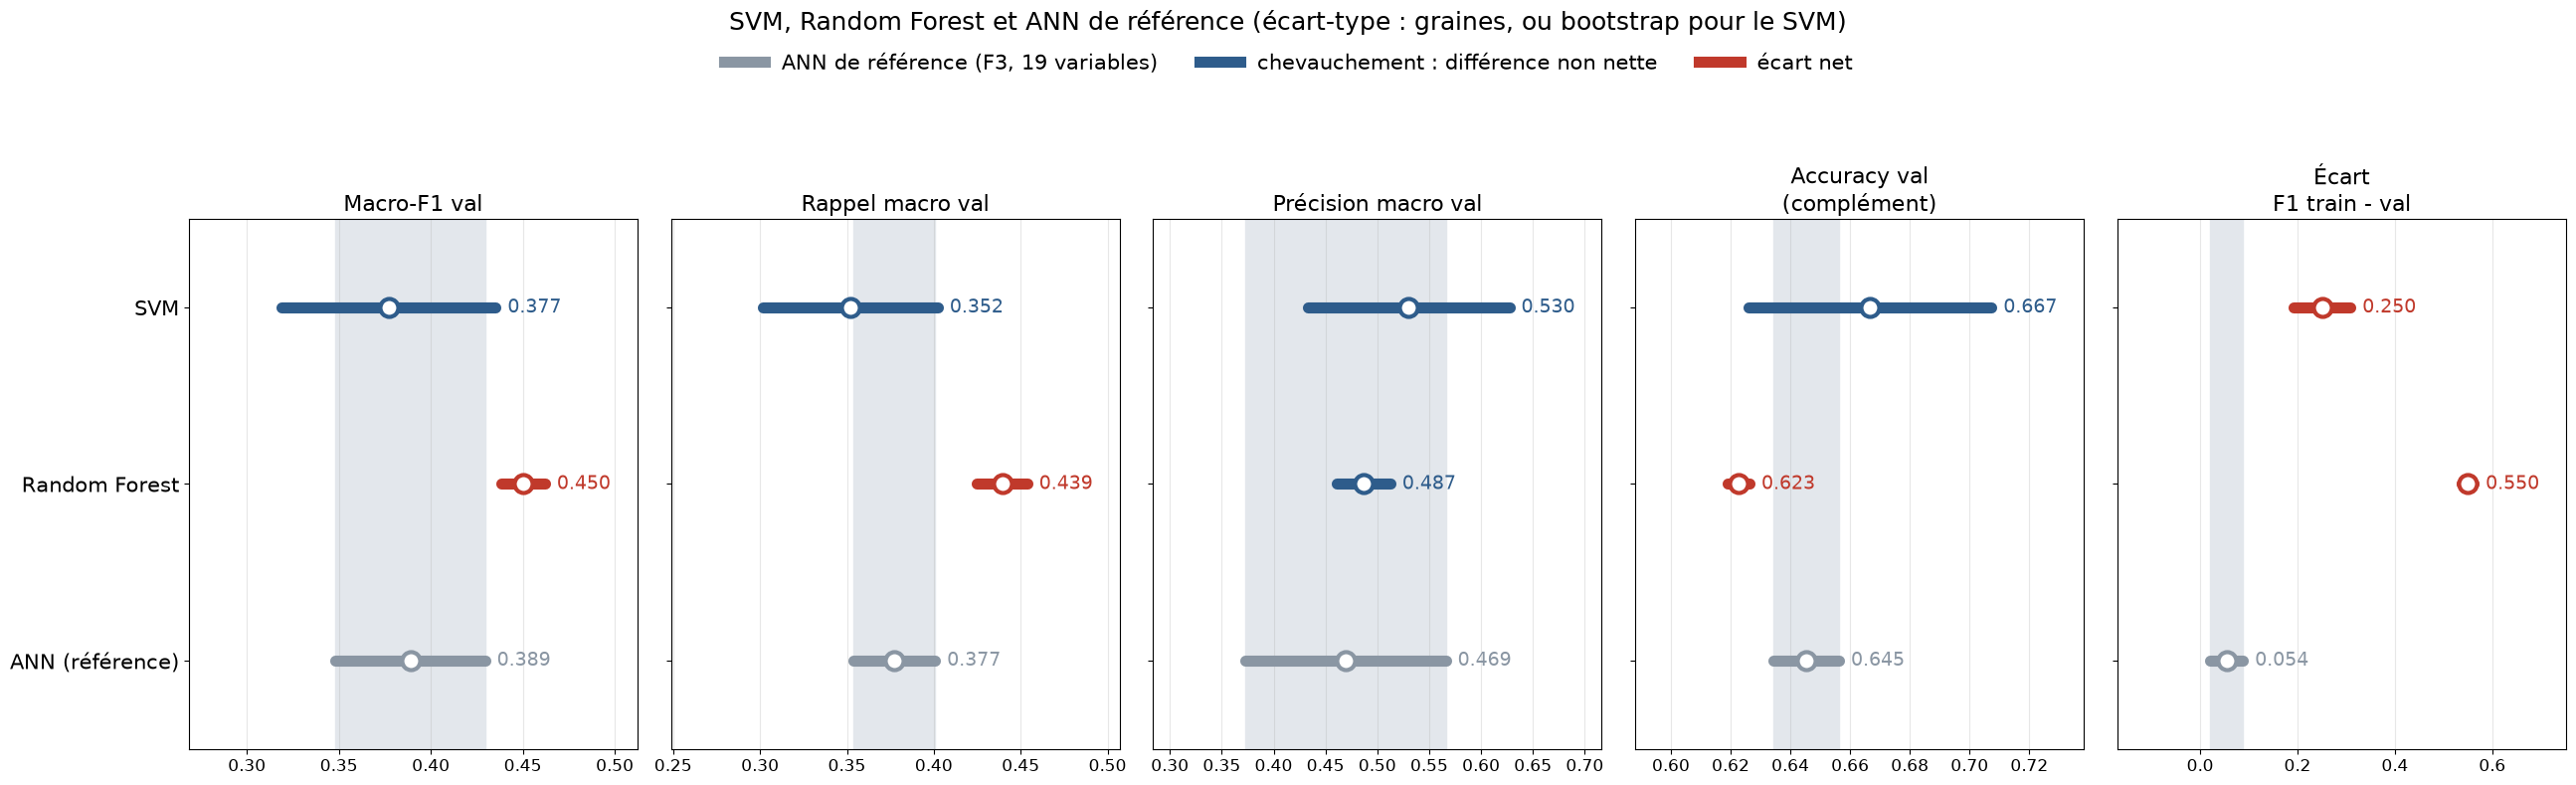

In [29]:
# Bandes de chevauchement : SVM et Random Forest contre l'ANN de référence

configs = [NOM_SVM, NOM_RF, REF_ANN]
criteres = [("val_f1_macro", "Macro-F1 val"), ("val_recall_macro", "Rappel macro val"),
            ("val_precision_macro", "Précision macro val"), ("val_accuracy", "Accuracy val\n(complément)"),
            ("ecart_f1_train_val", "Écart\nF1 train - val")]
stats = comparaison_svm.groupby("config")[[c for c, _ in criteres]].agg(["mean", "std"]).loc[configs]

fig, axes = plt.subplots(1, len(criteres), figsize=(26, 8), sharey=True)
y_pos = np.arange(len(configs))[::-1]
for ax, (col, titre) in zip(axes, criteres):
    m, s = stats[(col, "mean")], stats[(col, "std")].fillna(0).copy()
    cle = col if col != "ecart_f1_train_val" else "val_f1_macro"
    s[NOM_SVM] = max(s[NOM_SVM], ECARTS_SVM_FINAL[NOM_SVM][cle])          # incertitude bootstrap du SVM
    bas_ref, haut_ref = m[REF_ANN] - s[REF_ANN], m[REF_ANN] + s[REF_ANN]
    ax.axvspan(bas_ref, haut_ref, color="#e3e7ec")
    for yi, cfg in zip(y_pos, configs):
        bas, haut = m[cfg] - s[cfg], m[cfg] + s[cfg]
        c = "#8a96a3" if cfg == REF_ANN else ("#2e5c8b" if bas <= haut_ref and haut >= bas_ref else "#c0392b")
        ax.plot([bas, haut], [yi, yi], color=c, lw=8, solid_capstyle="round")
        ax.plot(m[cfg], yi, "o", color="white", mec=c, mew=3, ms=13)
        ax.text(haut, yi, f"  {m[cfg]:.3f}", va="center", fontsize=14, color=c)
    ax.set_title(titre, fontsize=16)
    ax.margins(x=0.35, y=0.25)
    ax.grid(axis="x", alpha=0.3)
    ax.tick_params(axis="x", labelsize=12)
axes[0].set_yticks(y_pos, configs)
axes[0].tick_params(axis="y", labelsize=15)
legende = [Line2D([0], [0], color="#8a96a3", lw=8, label="ANN de référence (F3, 19 variables)"),
           Line2D([0], [0], color="#2e5c8b", lw=8, label="chevauchement : différence non nette"),
           Line2D([0], [0], color="#c0392b", lw=8, label="écart net")]
fig.legend(handles=legende, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 0.95), frameon=False, fontsize=15)
fig.suptitle("SVM, Random Forest et ANN de référence (écart-type : graines, ou bootstrap pour le SVM)", fontsize=18)
plt.tight_layout(rect=[0, 0, 1, 0.86])
plt.savefig(os.path.join(DOSSIER_SVM, "chevauchement_ann_rf.png"), dpi=200, bbox_inches="tight")
plt.show()

Le SVM ne se distingue nettement de l’ANN sur aucun critère : tous les intervalles se chevauchent. Il est en revanche nettement dépassé par la forêt aléatoire en Macro-F1 et en rappel macro  : il retrouve moins bien les classes, surtout les classes minoritaires. À l’inverse, il obtient en moyenne la meilleure précision (0,530) et la meilleure accuracy (0,667).il se trompe rarement quand il prédit une classe, mais passe à côté de beaucoup d’observations rares comme l'on l'a observé il y'a de cela peu.Enfin, son écart-type bootstrap élevé (0,058 sur le Macro-F1) montre que son score est fragile : il varierait sensiblement avec une autre validation de même taille.

#### F1 par classe et matrice de confusion

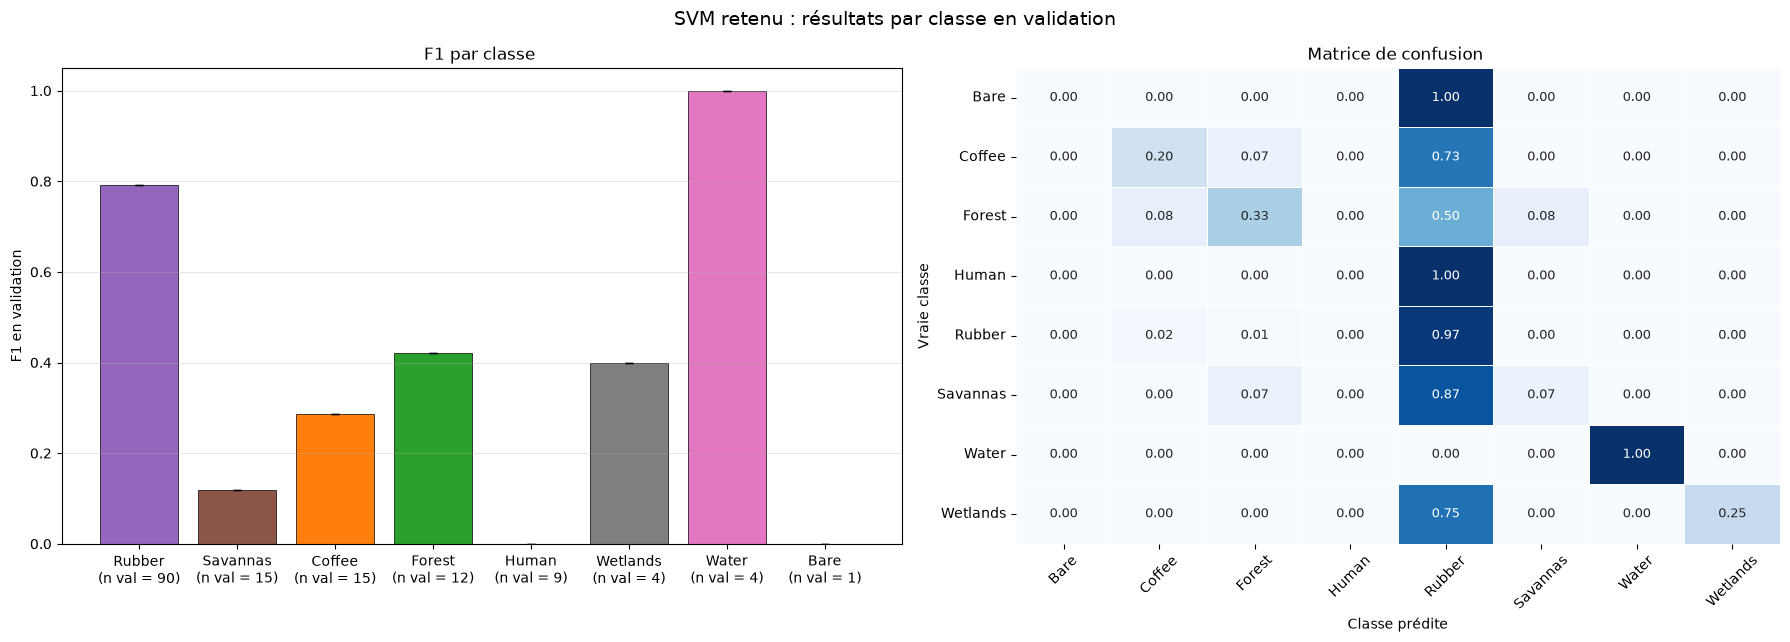

In [30]:
f1s = np.array([f1_classes_svm[g] for g in GRAINES])[:, ordre_classes]
fig, axes = plt.subplots(1, 2, figsize=(18, 6.5), gridspec_kw={"width_ratios": [1.1, 1]})
axes[0].bar(range(N_CLASSES), f1s.mean(axis=0), yerr=f1s.std(axis=0), capsize=3,
            color=[COULEURS_CLASSES[NOMS_CLASSES[k]] for k in ordre_classes], edgecolor="black", lw=0.5)
axes[0].set_xticks(range(N_CLASSES), [f"{noms_courts[k]}\n(n val = {np.sum(y_val == k)})" for k in ordre_classes])
axes[0].set_ylim(0, 1.05)
axes[0].set_ylabel("F1 en validation")
axes[0].grid(axis="y", alpha=0.3)
axes[0].set_title("F1 par classe ")

cm = sum(confusion_matrix(y_val, predictions_svm[g], labels=range(N_CLASSES)) for g in GRAINES)
sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False,
            xticklabels=noms_courts, yticklabels=noms_courts, annot_kws={"fontsize": 9},
            linewidths=0.5, linecolor="white", ax=axes[1])
axes[1].set_xlabel("Classe prédite")
axes[1].set_ylabel("Vraie classe")
axes[1].tick_params(axis="x", rotation=45)
axes[1].tick_params(axis="y", rotation=0)
axes[1].set_title("Matrice de confusion ")
fig.suptitle("SVM retenu : résultats par classe en validation", fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(DOSSIER_SVM, "f1_classes_confusion.png"), dpi=150)
plt.show()

La matrice de confusion confirme que le SVM classe la plupart des observations minoritaires comme Rubber : 87 % des Savannas, 75 % des Wetlands, 73 % des Coffee et la totalité des Human et Bare Soil. Ses F1 restent moyens pour Forest (0,42), Wetlands (0,40) et Coffee (0,29) parce qu’il prédit rarement ces classes, mais souvent à raison. Son rappel y est pourtant faible, au niveau de l’ANN et en dessous de la forêt. Seules Water (F1 = 1,00) et Rubber (0,79) sont bien reconnues. Le SVM est donc un modèle prudent : il se trompe peu quand il s’écarte de Rubber, mais il s’en écarte rarement.

#### Validation aléatoire et spatiale

f1_macro   rappel_macro       accuracy
config          validation                                             
ANN (référence) aléatoire   0.361 ± 0.033  0.350 ± 0.026  0.641 ± 0.011
                spatiale    0.288 ± 0.070  0.291 ± 0.074  0.636 ± 0.103
Random Forest   aléatoire   0.416 ± 0.060  0.400 ± 0.055  0.604 ± 0.049
                spatiale    0.333 ± 0.104  0.329 ± 0.101  0.601 ± 0.051
SVM             aléatoire   0.284 ± 0.056  0.279 ± 0.053  0.631 ± 0.021
                spatiale    0.182 ± 0.086  0.193 ± 0.067  0.599 ± 0.115

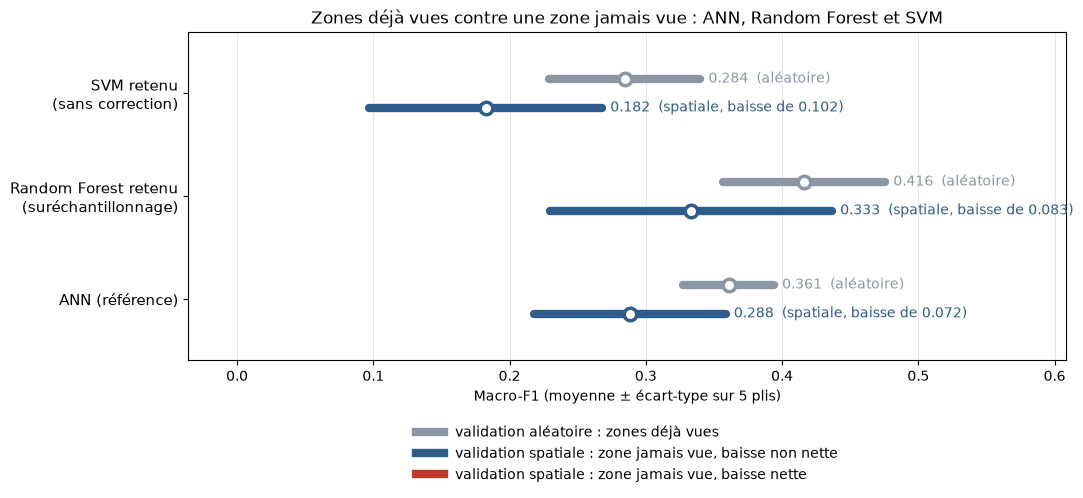

In [45]:
vc_svm = validation_croisee(lambda g: SVMDeseq(METHODE_SVM, PARAMS_SVM, g), NOM_SVM)
vc_svm.to_csv(os.path.join(DOSSIER_SVM, "validation_aleatoire_spatiale.csv"), index=False)
vc = pd.concat([ann_vc, vc_rf, vc_svm], ignore_index=True)
recap_vc = vc.groupby(["config", "validation"])[["f1_macro", "rappel_macro", "accuracy"]].agg(["mean", "std"])
tableau_vc = pd.DataFrame(index=recap_vc.index)
for c in ["f1_macro", "rappel_macro", "accuracy"]:
    tableau_vc[c] = [f"{m:.3f} ± {s:.3f}" for m, s in zip(recap_vc[(c, "mean")], recap_vc[(c, "std")])]
display(tableau_vc)

modeles_vc = [NOM_SVM, NOM_RF, REF_ANN]                            # de haut en bas
etiquettes_vc = {NOM_SVM: f"SVM retenu\n({METHODE_SVM.lower()})", NOM_RF: f"Random Forest retenu\n({METHODE_RF.lower()})",
                 REF_ANN: "ANN (référence)"}
fig, ax = plt.subplots(figsize=(11, 5.2))
for yi, config in enumerate(modeles_vc[::-1]):
    m_a, s_a = recap_vc.loc[(config, "aléatoire"), ("f1_macro", "mean")], recap_vc.loc[(config, "aléatoire"), ("f1_macro", "std")]
    m_s, s_s = recap_vc.loc[(config, "spatiale"), ("f1_macro", "mean")], recap_vc.loc[(config, "spatiale"), ("f1_macro", "std")]
    c_s = "#c0392b" if (m_s + s_s < m_a - s_a) else "#2e5c8b"
    for m, s, c, dy, nom in [(m_a, s_a, "#8a96a3", 0.14, "aléatoire"), (m_s, s_s, c_s, -0.14, "spatiale")]:
        ax.plot([m - s, m + s], [yi + dy, yi + dy], color=c, lw=6, solid_capstyle="round")
        ax.plot(m, yi + dy, "o", color="white", mec=c, mew=2.5, ms=9)
        ax.text(m + s, yi + dy, f"  {m:.3f}  ({nom}, baisse de {m_a - m_s:.3f})" if nom == "spatiale" else f"  {m:.3f}  ({nom})",
                va="center", fontsize=10, color=c)
ax.set_yticks(range(len(modeles_vc)), [etiquettes_vc[c] for c in modeles_vc[::-1]], fontsize=11)
ax.set_xlabel("Macro-F1 (moyenne ± écart-type sur 5 plis)")
ax.margins(x=0.35, y=0.2)
ax.grid(axis="x", alpha=0.3)
ax.legend(handles=[Line2D([0], [0], color="#8a96a3", lw=6, label="validation aléatoire : zones déjà vues"),
                   Line2D([0], [0], color="#2e5c8b", lw=6, label="validation spatiale : zone jamais vue, baisse non nette"),
                   Line2D([0], [0], color="#c0392b", lw=6, label="validation spatiale : zone jamais vue, baisse nette")],
          loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=1, frameon=False, fontsize=10)
ax.set_title("Zones déjà vues contre une zone jamais vue : ANN, Random Forest et SVM")
plt.tight_layout()
plt.savefig(os.path.join(DOSSIER_SVM, "validation_aleatoire_spatiale.png"), dpi=150)
plt.show()

Le SVM reste le moins performant des trois modèles, en zones connues (0,284) comme en zone nouvelle (0,182). Sa baisse en zone nouvelle (0,102) n’est pas nette, mais elle part du niveau le plus bas. Sans rééquilibrage, il abandonne les classes rares, qui deviennent presque absentes quand une zone est retirée.

#### Synthese modele de SVM

Le SVM retenu (noyau RBF, C = 1, gamma = 1, sans correction du déséquilibre) obtient un Macro-F1 de 0,377 ± 0,058 en validation, au niveau de l’ANN (chevauchement) mais nettement derrière la forêt aléatoire (0,450). 
C’est un modèle prudent : il a la meilleure précision (0,530) et la meilleure accuracy (0,667), mais il classe la plupart des observations minoritaires comme Rubber et ne reconnaît jamais Human ni Bare Soil. Aucune méthode de rééquilibrage ne l’améliore. 

Limites : son score est fragile (pic isolé dans la grille, incertitude bootstrap élevée) et se généralise mal, puisqu’il chute à 0,284 en validation croisée aléatoire et à 0,182 en zone nouvelle, le niveau le plus bas des trois modèles. Sa configuration est figée dans config_svm.json pour la comparaison finale.

#### Configuration finale

Enregistrée dans `resultats/modeles_finaux/config_svm.json`.

In [33]:
# Configuration finale du SVM, figée avant le test final
def moyenne_ecart(serie):
    return {"moyenne": round(float(serie.mean()), 3), "ecart_type": round(float(serie.std()), 3)}

# Résultats de la validation aléatoire et spatiale, relus depuis le fichier enregistré en SVM.8
vc_lu = pd.read_csv(os.path.join("resultats", "modeles_classiques", "svm", "validation_aleatoire_spatiale.csv"))

CONFIG_SVM_FINAL = {
    "modele": "SVM",
    "noyau": "rbf",
    "hyperparametres": PARAMS_SVM,
    "choix_hyperparametres": "meilleur Macro-F1 en validation parmi la grille (SVM déterministe : une évaluation)",
    "grille": {k: [str(x) for x in v] for k, v in GRILLE_SVM.items()},
    "desequilibre": METHODE_SVM,
    "desequilibre_application": "entraînement seulement (validation et test intacts)",
    "desequilibre_regle": "changement seulement si gain net de Macro-F1 sur « Sans correction » (même règle que l'ANN)",
    "variables": VARIABLES,
    "n_variables": len(VARIABLES),
    "standardisation": "StandardScaler appris sur l'entraînement (indispensable pour le SVM)",
    "graines": GRAINES,
    "seed_partition": SEED_PARTITION,
    "validation_fixe": {                                  # 150 observations ; SVM déterministe
        "f1_macro": moyenne_ecart(resultats_svm["val_f1_macro"]),
        "rappel_macro": moyenne_ecart(resultats_svm["val_recall_macro"]),
        "precision_macro": moyenne_ecart(resultats_svm["val_precision_macro"]),
        "accuracy": moyenne_ecart(resultats_svm["val_accuracy"]),
        "f1_macro_ecart_type_bootstrap": round(float(ECARTS_SVM_FINAL[NOM_SVM]["val_f1_macro"]), 3),
    },
    "validation_croisee_dev": {                           # 5 plis, entraînement + validation
        schema: moyenne_ecart(vc_lu.loc[vc_lu["validation"] == schema, "f1_macro"])
        for schema in ["aléatoire", "spatiale"]},
}

os.makedirs(DOSSIER_FINAL, exist_ok=True)
with open(os.path.join(DOSSIER_FINAL, "config_svm.json"), "w", encoding="utf-8") as f:
    json.dump(CONFIG_SVM_FINAL, f, ensure_ascii=False, indent=2, default=str)
print(json.dumps({k: v for k, v in CONFIG_SVM_FINAL.items() if k != "variables"}, ensure_ascii=False, indent=2, default=str))

{
  "modele": "SVM",
  "noyau": "rbf",
  "hyperparametres": {
    "C": 1,
    "gamma": 1
  },
  "choix_hyperparametres": "meilleur Macro-F1 en validation parmi la grille (SVM déterministe : une évaluation)",
  "grille": {
    "C": [
      "0.1",
      "1",
      "10",
      "100"
    ],
    "gamma": [
      "scale",
      "0.01",
      "0.1",
      "1"
    ]
  },
  "desequilibre": "Sans correction",
  "desequilibre_application": "entraînement seulement (validation et test intacts)",
  "desequilibre_regle": "changement seulement si gain net de Macro-F1 sur « Sans correction » (même règle que l'ANN)",
  "n_variables": 19,
  "standardisation": "StandardScaler appris sur l'entraînement (indispensable pour le SVM)",
  "graines": [
    0,
    1,
    2,
    3,
    4
  ],
  "seed_partition": 42,
  "validation_fixe": {
    "f1_macro": {
      "moyenne": 0.377,
      "ecart_type": 0.0
    },
    "rappel_macro": {
      "moyenne": 0.352,
      "ecart_type": 0.0
    },
    "precision_macro": {
   